# TIB S1/S3 — quyết định 120 mẫu, chờ freeze cohort/protocol

**Không chạy lại pilot. Notebook này chưa sẵn sàng chạy benchmark chính thức.** Quy mô đã duyệt: **120 mẫu, 40 ngắn / 40 vừa / 40 dài**, cùng S1/S3, một cấu hình × một lần (240 summaries). Formal selected/evaluated hiện **0/0**; ID/protocol chưa khóa. Cell đầu in quyết định ngay trong output, không cần mở JSON.

Pilot [rq2-tib-technical-pilot-colab.ipynb](rq2-tib-technical-pilot-colab.ipynb) đã chạy 9 train, 18/18 arms, 9/9 cặp cho mỗi metric, failed 0. Giữ notebook đó nguyên vẹn làm bằng chứng; chín ID development không đưa vào evaluation.

Dự báo cho 120: **5,00h central / 8,37h upper scenario** trên T4 **batch 2**, gồm init, chuẩn bị, hai arms, ba scorers, checkpoint và margin 30%. Không bảo đảm thời gian, không là CI/power. **8.769 là pool ứng viên**, không phải số mẫu sẽ benchmark.

**Run all hiện dừng trước cài thư viện, tải data/model hoặc dùng GPU.** Sau khi review nhóm nguồn, chọn và khóa 120 ID/hash cùng protocol, cần cập nhật notebook để ràng buộc cohort và scorer/group-analysis đã duyệt. Không đổi cờ để bỏ qua gate. Các cell phía dưới và output chuẩn bị cũ là **historical implementation**, không chứng minh đã chạy 120 mẫu.

Nguồn quyết định: `experiments/registry/datasets/tib-rq2-rq4-120-decision-261010.json`, ID `TIB-RQ2-RQ4-120-20261010`. S3 dùng lexical-boundary chunks rồi cùng flattened map/reduce như S1; không có riêng hierarchy-synthesis ablation. Claim giới hạn ở creator-abstract agreement và chi phí pipeline văn bản; references đã quan sát trong EDA.


In [ ]:
# Executed locally: decision display only; no dataset/model/GPU execution.
DECISION_ID = "TIB-RQ2-RQ4-120-20261010"
NOTEBOOK_EXECUTION_STATUS = "BLOCKED_PENDING_COHORT_AND_PROTOCOL_FREEZE"

def require_frozen_cohort():
    # Deliberately unconditional: a scale approval is not an execution protocol.
    # Replace this gate only with reviewed ID/hash/group/scorer binding after freeze.
    raise RuntimeError(
        "HOLD: 120 mẫu đã duyệt về quy mô; ID/protocol chưa freeze. "
        "Không chạy benchmark hoặc tải full pool. Không cần rerun pilot."
    )

print("QUYẾT ĐỊNH:", DECISION_ID)
print("Trạng thái notebook:", NOTEBOOK_EXECUTION_STATUS)
print("Hạng mục                     | Giá trị")
print("Pool ứng viên                | 8.769 (900 flagged được giữ)")
print("Pilot đã thực thi            | 9 train; 18/18 arms; 9/9 cặp mỗi metric; failed 0")
print("Mục tiêu evaluation          | 120 = 40 ngắn + 40 vừa + 40 dài")
print("Ngưỡng source tokens         | ngắn ≤4.271; vừa 4.272–7.142; dài >7.142")
print("Arms / summaries             | S1 + S3 / dự kiến 240; 1 cấu hình × 1 lần")
print("Formal selected / evaluated  | 0 / 0; cohort và protocol chưa freeze")
print("Profile để dự báo            | Tesla T4; FP16; map batch 2; greedy seed 42")
print("Dự báo gồm margin 30%        | 5,00h central / 8,37h upper scenario; không bảo đảm")
print("Reference exposure           | Đã quan sát trong EDA; không gọi unseen")
print("Tiếp theo                    | Review source groups → chọn ID độc lập điểm → freeze hashes/protocol")
print("Run all sẽ dừng tại gate trước khi cài thư viện/tải dữ liệu/model.")


QUYẾT ĐỊNH: TIB-RQ2-RQ4-120-20261010
Trạng thái notebook: BLOCKED_PENDING_COHORT_AND_PROTOCOL_FREEZE
Hạng mục                     | Giá trị
Pool ứng viên                | 8.769 (900 flagged được giữ)
Pilot đã thực thi            | 9 train; 18/18 arms; 9/9 cặp mỗi metric; failed 0
Mục tiêu evaluation          | 120 = 40 ngắn + 40 vừa + 40 dài
Ngưỡng source tokens         | ngắn ≤4.271; vừa 4.272–7.142; dài >7.142
Arms / summaries             | S1 + S3 / dự kiến 240; 1 cấu hình × 1 lần
Formal selected / evaluated  | 0 / 0; cohort và protocol chưa freeze
Profile để dự báo            | Tesla T4; FP16; map batch 2; greedy seed 42
Dự báo gồm margin 30%        | 5,00h central / 8,37h upper scenario; không bảo đảm
Reference exposure           | Đã quan sát trong EDA; không gọi unseen
Tiếp theo                    | Review source groups → chọn ID độc lập điểm → freeze hashes/protocol
Run all sẽ dừng tại gate trước khi cài thư viện/tải dữ liệu/model.


In [1]:
require_frozen_cohort()  # Current decision is pending; no data/model execution.
import importlib.util
import subprocess
import sys
required = {'datasets':'datasets', 'pandas':'pandas', 'matplotlib':'matplotlib',
            'transformers':'transformers', 'tqdm':'tqdm',
            'sentence_transformers':'sentence-transformers', 'numpy':'numpy',
            'bert_score':'bert-score', 'sentencepiece':'sentencepiece'}
missing = [package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from tqdm.auto import tqdm

## Historical implementation — không phải lệnh chạy hiện tại

Output bên dưới được giữ từ lần chuẩn bị cũ; không phải kết quả cohort 120. Mọi bước tải hoặc chạy đều bị chặn đến khi notebook được cập nhật sau freeze.


In [2]:
require_frozen_cohort()  # Current decision is pending; no data/model execution.
import os
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
USE_GOOGLE_DRIVE = IN_COLAB and os.environ.get('RQ2_TIB_USE_GOOGLE_DRIVE', '1') != '0'
REBUILD_DATA = False
MODEL_ID = 'Qwen/Qwen2.5-1.5B-Instruct'
MODEL_REVISION = '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_DIR = Path('/content/drive/MyDrive/RQ2_TIB_120_PENDING_FREEZE')
else:
    default_output = Path('/content/RQ2_TIB_120_PENDING_FREEZE') if IN_COLAB else Path.cwd() / 'experiments/outputs/rq2_tib_120_pending_freeze'
    OUTPUT_DIR = Path(os.environ.get('RQ2_TIB_OUTPUT_DIR', str(default_output)))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BUNDLE_PATH = OUTPUT_DIR / 'tib-120-frozen-data.jsonl.gz'
BENCHMARK_CONFIG = {
    'arms': {'S1':'fixed_chunk', 'S3':'source_only_predicted_hierarchy'},
    'generator': {'id':MODEL_ID,'revision':MODEL_REVISION},
    'tokenizer': {'id':MODEL_ID,'revision':MODEL_REVISION},
    'chunk_tokens':512, 'map_max_new_tokens':96, 'final_max_new_tokens':384,
    'temperature':0.0, 'seed':42, 'source_policy':'full_source_chunked',
    'budget_policy':'equal_total_map_output_and_final_cap_common_prompt_cap',
    'primary_metric':'rouge_l_f1_against_creator_abstract',
    'paired_analysis':{'contrast':'S3-S1','bootstrap_samples':5000,'seed':20261009},
}
print('Data file:',BUNDLE_PATH)
display(pd.DataFrame([{'setting':key,'value':value} for key,value in BENCHMARK_CONFIG.items()]))

Data file: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\benchmark\experiments\outputs\rq2_tib_benchmark\limited\tib-benchmark-data.jsonl.gz


,setting,value
0,arms,"{'S1': 'fixed_chunk', 'S3': 'source_only_predicted_hierarchy'}"
1,generator,"{'id': 'Qwen/Qwen2.5-1.5B-Instruct', 'revision': '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'}"
2,tokenizer,"{'id': 'Qwen/Qwen2.5-1.5B-Instruct', 'revision': '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'}"
3,chunk_tokens,512
4,map_max_new_tokens,96
5,final_max_new_tokens,384
6,temperature,0.0
7,seed,42
8,source_policy,full_source_chunked
9,budget_policy,equal_total_map_output_and_final_cap_common_prompt_cap


## 2. Mã xử lý dùng lại

Các module được nhúng để notebook chạy độc lập. `load_or_prepare_data` là cùng một hàm được gọi trực tiếp bên trong `run_benchmark`; notebook chuẩn bị riêng chỉ là tùy chọn.


In [3]:
METRICS_SOURCE = '"""Pinned semantic evaluation, preserving every token of long inputs.\n\nBERTScore uses its official implementation for encoder-sized inputs; longer\nabstracts/summaries use the same token alignment over contextual windows.\nSBERTScore is Ye et al. (2024) sentence precision, not a factuality percentage.\n"""\n\nimport importlib.metadata\nimport re\nimport time\n\nBERT_MODEL = "FacebookAI/xlm-roberta-large"\nBERT_REVISION = "c23d21b0620b635a76227c604d44e43a9f0ee389"\nSBERT_MODEL = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"\nSBERT_REVISION = "4328cf26390c98c5e3c738b4460a05b95f4911f5"\n\n\ndef sentences(text):\n    """Deterministic multilingual punctuation/newline splitter, no resource download."""\n    return [part.strip() for part in re.split(r"(?<=[.!?])\\s+|(?<=[。！？])\\s*|[\\r\\n]+", text) if part.strip()]\n\n\ndef _normalize(vectors):\n    import numpy as np\n    vectors = np.asarray(vectors, dtype=np.float32)\n    return vectors / np.maximum(np.linalg.norm(vectors, axis=-1, keepdims=True), 1e-12)\n\n\ndef token_alignment_f1(candidate, reference, block_size=256, candidate_weights=None, reference_weights=None):\n    """Unweighted BERTScore: greedy cosine alignment, then harmonic P/R."""\n    import numpy as np\n    if not len(candidate) or not len(reference):\n        return 0.0\n    candidate, reference = _normalize(candidate), _normalize(reference)\n    precision = np.full(len(candidate), -np.inf)\n    recall = np.full(len(reference), -np.inf)\n    for i in range(0, len(candidate), block_size):\n        for j in range(0, len(reference), block_size):\n            similarity = candidate[i:i+block_size] @ reference[j:j+block_size].T\n            precision[i:i+len(similarity)] = np.maximum(precision[i:i+len(similarity)], similarity.max(axis=1))\n            recall[j:j+similarity.shape[1]] = np.maximum(recall[j:j+similarity.shape[1]], similarity.max(axis=0))\n    p = float(np.average(precision, weights=candidate_weights))\n    r = float(np.average(recall, weights=reference_weights))\n    return 2*p*r/(p+r) if abs(p+r) > 1e-12 else 0.0\n\n\nclass SemanticScorer:\n    """Reusable lazy encoders; test adapters expose the same tokenizer/encode interface."""\n\n    def __init__(self, *, device="cpu", batch_size=16, bert_adapter=None, sentence_adapter=None,\n                 on_event=None):\n        if batch_size < 1:\n            raise ValueError("batch_size must be positive")\n        self.device, self.batch_size = device, batch_size\n        self._bert, self._sentence = bert_adapter, sentence_adapter\n        self._injected = bert_adapter is not None or sentence_adapter is not None\n        self.on_event = on_event\n\n    def _emit(self, **event):\n        if self.on_event is not None:\n            self.on_event(event)\n\n    def load(self):\n        """Load the pinned encoders explicitly before evaluating records."""\n        self._load()\n        return self\n\n    @property\n    def metadata(self):\n        versions = {}\n        for package in ("bert-score", "sentence-transformers", "transformers", "torch", "numpy"):\n            try:\n                versions[package] = importlib.metadata.version(package)\n            except importlib.metadata.PackageNotFoundError:\n                versions[package] = "not_installed"\n        return {"version": "tib_semantic_v1", "packages": versions, "device": self.device,\n                "batch_size": self.batch_size, "test_adapters": self._injected,\n                "bertscore": {"model": BERT_MODEL, "revision": BERT_REVISION,\n                              "tokenizer_revision": BERT_REVISION, "layer": 17,\n                              "idf": False, "rescale_with_baseline": False,\n                              "long_input": "nonoverlapping_510_token_context_windows_global_alignment",\n                              "implementation": "official_bert_score_short_custom_same_alignment_long",\n                              "max_tokens": 512, "special_tokens_excluded": "aggregation_only_zero_weight_kept_as_alignment_targets"},\n                "sbertscore": {"model": SBERT_MODEL, "revision": SBERT_REVISION,\n                               "tokenizer_revision": SBERT_REVISION,\n                               "formula": "mean_summary_sentence_max_source_sentence_cosine",\n                               "sentence_splitter": "latin_punctuation_whitespace_cjk_punctuation_or_newline_v1",\n                               "long_sentence": "token_weighted_mean_of_all_context_windows_then_l2",\n                               "source_coverage": "all_sentences_batched_no_document_truncation"}}\n\n    def _load(self):\n        if self._bert is None:\n            started = time.perf_counter()\n            self._emit(stage="model_loading", status="started", model=BERT_MODEL)\n            from bert_score import BERTScorer\n            from huggingface_hub import snapshot_download\n            path = snapshot_download(BERT_MODEL, revision=BERT_REVISION,\n                                     allow_patterns=["*.json", "*.safetensors", "*.model"])\n            self._bert = BERTScorer(model_type=path, num_layers=17, idf=False,\n                                   rescale_with_baseline=False, device=self.device,\n                                   batch_size=self.batch_size, use_fast_tokenizer=True)\n            self._emit(stage="model_loading", status="completed", model=BERT_MODEL,\n                       elapsed_seconds=time.perf_counter() - started)\n        if self._sentence is None:\n            started = time.perf_counter()\n            self._emit(stage="model_loading", status="started", model=SBERT_MODEL)\n            from sentence_transformers import SentenceTransformer\n            self._sentence = SentenceTransformer(SBERT_MODEL, revision=SBERT_REVISION, device=self.device)\n            self._emit(stage="model_loading", status="completed", model=SBERT_MODEL,\n                       elapsed_seconds=time.perf_counter() - started)\n\n    def _bert_tokens(self, text, *, include_special=False):\n        """Contextualize all tokens; specials have zero aggregation weight."""\n        import numpy as np\n        import torch\n        tokenizer = self._bert._tokenizer\n        ids = tokenizer.encode(text, add_special_tokens=False, truncation=False)\n        capacity = 512 - tokenizer.num_special_tokens_to_add(pair=False)\n        vectors, weights = [], []\n        for start in range(0, len(ids), capacity):\n            encoded = tokenizer.prepare_for_model(ids[start:start+capacity], return_tensors="pt",\n                                                  prepend_batch_axis=True, truncation=False)\n            # Pinned XLM-R single sequences have one inserted token on each end.\n            # Mask wrappers by position: content <unk>/<mask> IDs remain content.\n            if len(encoded["input_ids"][0]) != len(ids[start:start+capacity]) + 2:\n                raise ValueError("Expected pinned XLM-R single-sequence wrapper layout")\n            special = torch.zeros(len(encoded["input_ids"][0]), dtype=torch.bool)\n            special[0] = special[-1] = True\n            encoded = {key: value.to(self.device) for key, value in encoded.items()}\n            with torch.inference_mode():\n                hidden = self._bert._model(**encoded).last_hidden_state[0]\n            vectors.append((hidden if include_special else hidden[~special.to(hidden.device)]).float().cpu().numpy())\n            weights.extend((~special).tolist() if include_special else [1] * int((~special).sum()))\n        embeddings = np.concatenate(vectors) if vectors else np.empty((0, 1))\n        return (embeddings, weights) if include_special else embeddings\n\n    def _bertscore(self, hypothesis, reference):\n        if not hypothesis.strip() or not reference.strip():\n            return 0.0\n        tokenizer = self._bert._tokenizer\n        lengths = [len(tokenizer.encode(text, add_special_tokens=True, truncation=False))\n                   for text in (hypothesis, reference)]\n        if max(lengths) <= 512:\n            return float(self._bert.score([hypothesis], [reference], batch_size=self.batch_size)[2][0])\n        candidate, candidate_weights = self._bert_tokens(hypothesis, include_special=True)\n        target, reference_weights = self._bert_tokens(reference, include_special=True)\n        return token_alignment_f1(candidate, target, candidate_weights=candidate_weights,\n                                 reference_weights=reference_weights)\n\n    def _sentence_vectors(self, texts, *, arm=None, input_kind=None, sentence_offset=0):\n        """Batch all sentence windows, retaining one vector per original sentence."""\n        import numpy as np\n        tokenizer = self._sentence.tokenizer\n        capacity = self._sentence.max_seq_length - tokenizer.num_special_tokens_to_add(pair=False)\n        if capacity < 1:\n            raise ValueError("Sentence encoder has no content-token capacity")\n        parts, weights, owners = [], [], []\n        for owner, text in enumerate(texts):\n            offsets = tokenizer(text, add_special_tokens=False, truncation=False,\n                                return_offsets_mapping=True)["offset_mapping"]\n            if not offsets:\n                raise ValueError("Nonempty sentence produced no encoder tokens")\n            window_count = (len(offsets) + capacity - 1) // capacity\n            if window_count > 1:\n                self._emit(stage="sentence_windows", status="started", arm=arm,\n                           input_kind=input_kind, sentence_index=sentence_offset + owner + 1,\n                           token_count=len(offsets), window_count=window_count)\n            for start in range(0, len(offsets), capacity):\n                window = offsets[start:start+capacity]\n                parts.append(text[window[0][0]:window[-1][1]])\n                weights.append(len(window))\n                owners.append(owner)\n        # Bound GPU encode batches even for unusually long unpunctuated sentences.\n        totals, counts = {}, {}\n        for start in range(0, len(parts), self.batch_size):\n            chunk = parts[start:start+self.batch_size]\n            for part in chunk:\n                if len(tokenizer.encode(part, truncation=False)) > self._sentence.max_seq_length:\n                    raise ValueError("Retokenized sentence window exceeds capacity; no truncation allowed")\n            vectors = self._sentence.encode(chunk, batch_size=self.batch_size,\n                                            convert_to_numpy=True, normalize_embeddings=False,\n                                            show_progress_bar=False)\n            for i, vector in enumerate(vectors, start):\n                owner, weight = owners[i], weights[i]\n                totals[owner] = totals.get(owner, 0) + np.asarray(vector) * weight\n                counts[owner] = counts.get(owner, 0) + weight\n        return _normalize([totals[i] / counts[i] for i in range(len(texts))]) if texts else np.empty((0, 1))\n\n    def score_pair(self, arms, reference, transcript):\n        import numpy as np\n        self._load()\n        bert = {}\n        for arm in ("S1", "S3"):\n            started = time.perf_counter()\n            self._emit(stage="bertscore", status="started", arm=arm)\n            bert[arm] = self._bertscore(arms[arm]["summary"], reference)\n            self._emit(stage="bertscore", status="completed", arm=arm, score=bert[arm],\n                       elapsed_seconds=time.perf_counter() - started)\n        sbert_started = time.perf_counter()\n        summary_vectors = {arm: self._sentence_vectors(sentences(arms[arm]["summary"]),\n                                                      arm=arm, input_kind="summary")\n                           for arm in ("S1", "S3")}\n        maxima = {arm: np.full(len(vectors), -np.inf) for arm, vectors in summary_vectors.items()}\n        source = sentences(transcript)\n        self._emit(stage="source_embedding", status="started", processed_sentences=0,\n                   total_sentences=len(source))\n        for start in range(0, len(source), self.batch_size):\n            started = time.perf_counter()\n            vectors = self._sentence_vectors(source[start:start+self.batch_size],\n                                            input_kind="source", sentence_offset=start)\n            for arm, summary in summary_vectors.items():\n                if len(summary):\n                    maxima[arm] = np.maximum(maxima[arm], (summary @ vectors.T).max(axis=1))\n            self._emit(stage="source_embedding", status="completed",\n                       processed_sentences=min(start + self.batch_size, len(source)),\n                       total_sentences=len(source), elapsed_seconds=time.perf_counter() - started)\n        sbert = {arm: float(values.mean()) if len(values) and source else 0.0\n                 for arm, values in maxima.items()}\n        for arm in ("S1", "S3"):\n            self._emit(stage="sbertscore", status="completed", arm=arm, score=sbert[arm],\n                       elapsed_seconds=time.perf_counter() - sbert_started)\n        for metric in (bert, sbert):\n            metric["S3_minus_S1"] = metric["S3"] - metric["S1"]\n        return {"bertscore": bert, "sbertscore": sbert}\n'
PAIR_SOURCE = '"""Shared-source S1/S3 execution, equal output allocations and partial usage."""\n\nimport hashlib\nimport sys\nimport time\n\nfrom experiments.scripts.rq2_controlled_validation import (\n    RunConfig, _call, _fixed_chunks, _hierarchy_chunks, predict_source_boundaries,\n)\n\n\nclass PairGenerationError(RuntimeError):\n    def __init__(self, message, partial_arm):\n        super().__init__(message)\n        self.partial_arm = partial_arm\n        self.partial_pair = {}\n\n\ndef _prompts(chunks):\n    return [f"Summarize lecture section {i} using only its source.\\nCONTENT:\\n{chunk}\\nSECTION SUMMARY:"\n            for i, chunk in enumerate(chunks, 1)]\n\n\ndef _cuda_meter(backend):\n    """Measure an already initialized CUDA backend without importing torch."""\n    torch = sys.modules.get("torch")\n    if torch is None or not str(getattr(backend, "device", "")).startswith("cuda"):\n        return None\n    cuda = torch.cuda\n    if not cuda.is_available() or not cuda.is_initialized():\n        return None\n    try:\n        cuda.synchronize()\n        cuda.reset_peak_memory_stats()\n    except RuntimeError:\n        return None\n    return cuda\n\n\ndef _emit(on_event, **event):\n    if on_event is not None:\n        on_event(event)\n\n\nclass _BatchResponse:\n    """Replay one generated response through the shared exact-usage validator."""\n\n    def __init__(self, backend, response):\n        self.count_tokens = backend.count_tokens\n        self.response = response\n\n    def generate(self, prompt, **kwargs):\n        return self.response\n\n\ndef _map_groups(prompts, limits, size):\n    # One model dispatch has a common max_new_tokens. Never round the per-chunk\n    # allocation upward to combine the two caps produced by divmod.\n    start = 0\n    while start < len(prompts):\n        end = start + 1\n        while end < len(prompts) and end - start < size and limits[end] == limits[start]:\n            end += 1\n        yield start, prompts[start:end], limits[start]\n        start = end\n\n\ndef _summarize(chunks, backend, call_config, map_budget, final_budget, segmentation_seconds,\n               arm=None, on_event=None):\n    # Both arms get exactly the same total map-output allocation, distributed\n    # across their actual chunk count; final output cap is also identical.\n    base, remainder = divmod(map_budget, len(chunks))\n    limits = [base + (i < remainder) for i in range(len(chunks))]\n    calls, sections = [], []\n    summary, error, call_count = None, None, 0\n    request_count = 0\n    batch_size = getattr(backend, "map_batch_size", 1)\n    if not isinstance(batch_size, int) or isinstance(batch_size, bool) or batch_size < 1:\n        raise ValueError("Map batch size must be a positive integer")\n    if not callable(getattr(backend, "generate_batch", None)):\n        batch_size = 1\n    cuda = _cuda_meter(backend)\n    generation_start = time.perf_counter()\n    step, chunk_index = "map", None\n    try:\n        for start, prompts, limit in _map_groups(_prompts(chunks), limits, batch_size):\n            chunk_index = start + 1\n            step_start = time.perf_counter()\n            details = {"batch_size": len(prompts), "chunk_end": start + len(prompts)}\n            _emit(on_event, stage="generation", status="started", arm=arm, step="map",\n                  chunk_index=chunk_index, chunk_total=len(chunks), **details)\n            call_count += len(prompts)\n            request_count += 1\n            if len(prompts) == 1:\n                sections.append(_call(backend, prompts[0], call_config, calls, output_limit=limit))\n            else:\n                responses = backend.generate_batch(prompts, max_output_tokens=limit,\n                    temperature=call_config.temperature, seed=call_config.seed)\n                if not isinstance(responses, list) or len(responses) != len(prompts):\n                    raise ValueError("Batch backend returned the wrong number of responses")\n                for offset, (prompt, response) in enumerate(zip(prompts, responses)):\n                    chunk_index = start + offset + 1\n                    sections.append(_call(_BatchResponse(backend, response), prompt,\n                                          call_config, calls, output_limit=limit))\n            _emit(on_event, stage="generation", status="completed", arm=arm, step="map",\n                  chunk_index=start + 1, chunk_total=len(chunks),\n                  elapsed_seconds=time.perf_counter() - step_start, **details)\n        prompt = "Synthesize these source-based section summaries.\\n" + "\\n".join(sections) + "\\nFINAL SUMMARY:"\n        step, chunk_index = "reduce", None\n        step_start = time.perf_counter()\n        _emit(on_event, stage="generation", status="started", arm=arm, step=step)\n        call_count += 1\n        request_count += 1\n        summary = _call(backend, prompt, call_config, calls, output_limit=final_budget)\n        _emit(on_event, stage="generation", status="completed", arm=arm, step=step,\n              elapsed_seconds=time.perf_counter() - step_start)\n    except (ValueError, RuntimeError, OSError) as exc:\n        error = exc\n        details = {"chunk_index": chunk_index, "chunk_total": len(chunks)} if step == "map" else {}\n        _emit(on_event, stage="generation", status="failed", arm=arm, step=step,\n              elapsed_seconds=time.perf_counter() - step_start, error_type=type(exc).__name__, **details)\n    allocated, reserved = None, None\n    if cuda is not None:\n        try:\n            cuda.synchronize()\n            allocated = int(cuda.max_memory_allocated())\n            reserved = int(cuda.max_memory_reserved())\n        except RuntimeError:\n            # Lost CUDA contexts leave memory measurements unavailable.\n            allocated, reserved = None, None\n    generation_seconds = time.perf_counter() - generation_start\n    receipt = {"summary": summary, "calls": calls, "chunk_count": len(chunks),\n            "section_summaries": sections, "status": "failed" if error else "completed",\n            "reused": False, "usage_complete": error is None,\n            "segmentation_seconds": segmentation_seconds,\n            "generation_seconds": generation_seconds,\n            "wall_seconds": segmentation_seconds + generation_seconds,\n            "call_count": call_count,\n            "generation_request_count": request_count,\n            "map_batch_size": batch_size,\n            "reported_attempt_count": len(calls),\n            "peak_gpu_allocated_bytes": allocated,\n            "peak_gpu_reserved_bytes": reserved,\n            "map_output_caps": limits, "map_output_budget": sum(limits),\n            "final_output_budget": final_budget,\n            "prompt_tokens": sum(call["prompt_tokens"] for call in calls),\n            "output_tokens": sum(call["output_tokens"] for call in calls)}\n    if error is not None:\n        wrapped = PairGenerationError(str(error), receipt)\n        wrapped.original_error_type = type(error).__name__\n        raise wrapped from error\n    return receipt\n\n\ndef run_source_pair(source, backend, config, completed_arms=None, on_progress=None, on_event=None):\n    """Consume a source-only adapter; references cannot enter either arm."""\n    config.validate()\n    preparation_start = time.perf_counter()\n    segments = source["transcript_segments"]\n    texts, starts = segments["text"], segments["start"]\n    normalized_source = " ".join(source["transcript"].split())\n    chunks_by_arm, segmentation_times = {}, {}\n    for arm in ("S1", "S3"):\n        segmentation_start = time.perf_counter()\n        _emit(on_event, stage="segmentation", status="started", arm=arm)\n        try:\n            if arm == "S1":\n                chunks = _fixed_chunks(normalized_source, backend, config.chunk_tokens)\n            else:\n                boundaries = predict_source_boundaries(texts, starts)\n                chunks = _hierarchy_chunks(texts, starts, boundaries, backend, config.chunk_tokens)\n        except (ValueError, RuntimeError, OSError) as exc:\n            _emit(on_event, stage="segmentation", status="failed", arm=arm,\n                  elapsed_seconds=time.perf_counter() - segmentation_start, error_type=type(exc).__name__)\n            raise\n        segmentation_times[arm] = time.perf_counter() - segmentation_start\n        chunks_by_arm[arm] = chunks\n        _emit(on_event, stage="segmentation", status="completed", arm=arm,\n              chunk_total=len(chunks), elapsed_seconds=segmentation_times[arm])\n    s1, s3 = chunks_by_arm["S1"], chunks_by_arm["S3"]\n    if not s1 or not s3 or any(" ".join(chunks) != normalized_source for chunks in (s1, s3)):\n        raise ValueError("The two arms must cover the identical complete source")\n    map_budget = max(len(s1), len(s3)) * config.map_output_tokens\n    # One common cumulative prompt cap accommodates full source plus map output;\n    # record actual usage separately instead of truncating long transcripts.\n    prompt_budget = max(sum(backend.count_tokens(p) for p in _prompts(chunks))\n                        for chunks in (s1, s3)) + 4 * map_budget + 2048\n    call_config = RunConfig(model_id=backend.model_id, tokenizer_id=backend.tokenizer_id,\n        max_source_tokens=backend.count_tokens(normalized_source),\n        cumulative_prompt_budget=prompt_budget, allowed_prompt_imbalance=prompt_budget,\n        chunk_tokens=config.chunk_tokens, max_output_tokens=config.map_output_tokens,\n        final_output_tokens=config.final_output_tokens, seed=config.seed, temperature=config.temperature)\n    context = {"source_tokens": backend.count_tokens(normalized_source),\n               "generation_source_sha256": hashlib.sha256(normalized_source.encode()).hexdigest(),\n               "predicted_boundaries_seconds": boundaries,\n               "boundary_predictor": "source_only_adjacent_window_lexical_cohesion_v1",\n               "common_cumulative_prompt_budget": prompt_budget}\n    # Recomputing reused arm chunks is needed for identical common budgets;\n    # charge it to this attempt\'s overhead, not to the original reused receipt.\n    fresh_segmentation = sum(seconds for name, seconds in segmentation_times.items()\n        if (completed_arms or {}).get(name, {}).get("status") != "completed")\n    context["shared_preparation_seconds"] = max(\n        0.0, time.perf_counter() - preparation_start - fresh_segmentation)\n    arms = {}\n    for name, chunks in (("S1", s1), ("S3", s3)):\n        previous = (completed_arms or {}).get(name)\n        if previous and previous.get("status") == "completed":\n            arms[name] = {**previous, "reused": True}\n            _emit(on_event, stage="generation", status="reused", arm=name)\n            if on_progress:\n                on_progress({**context, "arms": dict(arms)})\n            continue\n        try:\n            arms[name] = _summarize(chunks, backend, call_config, map_budget,\n                                    config.final_output_tokens, segmentation_times[name], name, on_event)\n        except PairGenerationError as exc:\n            arms[name] = exc.partial_arm\n            exc.partial_pair = {**context, "arms": arms}\n            raise\n        if on_progress:\n            on_progress({**context, "arms": dict(arms)})\n    return {**context, "arms": arms,\n            "prompt_imbalance_tokens": abs(arms["S1"]["prompt_tokens"] - arms["S3"]["prompt_tokens"])}\n'
PREPARATION_SOURCE = '"""Prepare pinned TIB text inputs for a limited RQ2 abstract-agreement benchmark.\n\nThis module returns data and audit tables in memory. It never qualifies creator\nabstracts as factual ground truth or silently truncates a transcript.\n"""\n\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport math\nimport re\nfrom collections import Counter, defaultdict\nfrom typing import Iterable, Mapping\n\nDATASET = "gigant/tib"\nREVISION = "e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee"\nSPLITS = ("train", "valid", "test")\nEXPECTED_COUNTS = {"train": 7282, "valid": 910, "test": 911}\n_RAW_FIELDS = {"source_text", "reference_text", "segment_texts", "segment_starts_seconds",\n               "segment_ends_seconds"}\n\n\ndef _text(value: object) -> str:\n    return str(value or "").strip()\n\n\ndef _normalized(value: object) -> str:\n    return " ".join(_text(value).casefold().split())\n\n\ndef _tokens(value: object) -> list[str]:\n    return re.findall(r"\\b\\w+\\b", _text(value).casefold())\n\n\ndef _digest(value: object) -> str:\n    payload = json.dumps(value, ensure_ascii=False, separators=(",", ":"))\n    return hashlib.sha256(payload.encode("utf-8")).hexdigest()\n\n\ndef prepare_record(split: str, source_index: int, record: Mapping) -> dict:\n    """Keep original segment content and explain every mechanical exclusion."""\n    if split not in SPLITS or not isinstance(source_index, int) or source_index < 0:\n        raise ValueError("A valid creator split and nonnegative source_index are required")\n    transcript = _text(record.get("transcript"))\n    abstract = _text(record.get("abstract"))\n    segments = record.get("transcript_segments")\n    segments = segments if isinstance(segments, Mapping) else {}\n    arrays = [segments.get(field) for field in ("text", "start", "end")]\n    aligned_arrays = all(isinstance(value, (list, tuple)) for value in arrays)\n    texts, starts, ends = (tuple(value) for value in arrays) if aligned_arrays else ((), (), ())\n    clean_texts = tuple(_text(value) for value in texts)\n    source_text = " ".join(clean_texts)\n    structural_reasons: list[str] = []\n    if not transcript:\n        structural_reasons.append("missing_transcript")\n    if len(texts) < 2:\n        structural_reasons.append("insufficient_segments")\n    if not aligned_arrays or len(texts) != len(starts) or len(texts) != len(ends):\n        structural_reasons.append("misaligned_segments")\n    if any(not text for text in clean_texts):\n        structural_reasons.append("empty_segment_text")\n    valid_times = (\n        aligned_arrays\n        and len(texts) == len(starts) == len(ends)\n        and all(\n            isinstance(start, (int, float)) and not isinstance(start, bool)\n            and isinstance(end, (int, float)) and not isinstance(end, bool)\n            and math.isfinite(start) and math.isfinite(end)\n            and 0 <= start <= end\n            for start, end in zip(starts, ends)\n        )\n    )\n    if not valid_times:\n        structural_reasons.append("invalid_segment_times")\n    elif any(starts[i] < starts[i - 1] for i in range(1, len(starts))):\n        structural_reasons.append("unordered_segments")\n    # Overlaps and text disagreement need review, but both arms can use the same\n    # ordered segment text; neither destroys a text-only source by itself.\n    overlap_count = (sum(starts[i] < ends[i - 1] for i in range(1, len(starts)))\n                     if valid_times and "unordered_segments" not in structural_reasons else None)\n    transcript_matches_segments = _tokens(transcript) == _tokens(source_text)\n    reference_reasons = [] if abstract else ["empty_abstract"]\n    flags = []\n    if not _text(record.get("doi")):\n        flags.append("missing_doi")\n    if not _text(record.get("url")):\n        flags.append("missing_source_url")\n    if abstract and len(abstract.split()) < 30:\n        flags.append("short_abstract_under_30_words")\n    if overlap_count:\n        flags.append("overlapping_segments")\n    if transcript and source_text and not transcript_matches_segments:\n        flags.append("transcript_segment_mismatch")\n    license_text = _text(record.get("license"))\n    source_url = _text(record.get("url"))\n    return {\n        "split": split, "source_index": source_index,\n        "doi": _text(record.get("doi")), "title": _text(record.get("title")),\n        "author": _text(record.get("author")), "genre": _text(record.get("genre")),\n        "subject": _text(record.get("subject")), "language": _text(record.get("language")),\n        "release_year": _text(record.get("release_year")),\n        "license_label": license_text.splitlines()[0] if license_text else "",\n        "source_url": source_url, "source_url_present": bool(source_url),\n        "video_url_present": bool(_text(record.get("video_url"))),\n        "transcript_words": len(transcript.split()),\n        "source_words": len(source_text.split()),\n        "abstract_words": len(abstract.split()), "segment_count": len(texts),\n        "duration_minutes": max(ends) / 60 if valid_times and ends else None,\n        "segment_overlap_count": overlap_count,\n        "transcript_matches_segments": transcript_matches_segments,\n        "source_text": source_text, "reference_text": abstract,\n        "segment_texts": clean_texts,\n        "segment_starts_seconds": tuple(float(x) for x in starts) if valid_times else (),\n        "segment_ends_seconds": tuple(float(x) for x in ends) if valid_times else (),\n        "source_sha256": hashlib.sha256(source_text.encode("utf-8")).hexdigest(),\n        "reference_sha256": hashlib.sha256(abstract.encode("utf-8")).hexdigest(),\n        "structural_reasons": structural_reasons,\n        "reference_reasons": reference_reasons,\n        "audit_flags": flags,\n        "text_usable": not structural_reasons,\n        "abstract_agreement_candidate": not structural_reasons and not reference_reasons,\n        "unique_reference_candidate": not structural_reasons and not reference_reasons,\n        "domain_status": "unverified",\n        "reference_status": "unverified_creator_abstract",\n    }\n\n\ndef load_pinned_splits(splits: Iterable[str]) -> dict[str, Iterable[Mapping]]:\n    """Stream explicitly requested creator splits; importing this module stays offline."""\n    requested = tuple(splits)\n    if not requested or len(set(requested)) != len(requested) or set(requested) - set(SPLITS):\n        raise ValueError("Specify distinct train/valid/test splits")\n    from datasets import load_dataset\n\n    return {\n        split: load_dataset(DATASET, split=split, revision=REVISION, streaming=True)\n        for split in requested\n    }\n\n\ndef prepare_dataset(rows_by_split: Mapping[str, Iterable[Mapping]], *,\n                    verify_counts: bool = True) -> dict:\n    """Build a deterministic audit and mechanical candidates without file output."""\n    if not rows_by_split or set(rows_by_split) - set(SPLITS):\n        raise ValueError("Unknown or empty creator split selection")\n    records = [\n        prepare_record(split, index, record)\n        for split in SPLITS if split in rows_by_split\n        for index, record in enumerate(rows_by_split[split])\n    ]\n    counts = {split: sum(row["split"] == split for row in records)\n              for split in SPLITS if split in rows_by_split}\n    if verify_counts and any(count != EXPECTED_COUNTS[split] for split, count in counts.items()):\n        raise ValueError(f"Pinned TIB row count changed: {counts}")\n    shared_groups: dict[str, int] = {}\n    for field in ("doi", "title", "author"):\n        groups: dict[str, list[dict]] = defaultdict(list)\n        for row in records:\n            key = _normalized(row[field])\n            if key:\n                groups[key].append(row)\n        shared = [group for group in groups.values()\n                  if len({row["split"] for row in group}) > 1]\n        shared_groups[field] = len(shared)\n        for group in shared:\n            for row in group:\n                row["audit_flags"].append(f"cross_split_{field}_group")\n    references: dict[str, list[dict]] = defaultdict(list)\n    for row in records:\n        key = _normalized(row["reference_text"])\n        if key and row["text_usable"]:\n            references[key].append(row)\n    for group in references.values():\n        if len(group) > 1:\n            # A reused abstract cannot distinguish the content of individual talks.\n            cross_split = len({row["split"] for row in group}) > 1\n            for row in group:\n                row["audit_flags"].append("shared_abstract_group")\n                if cross_split:\n                    row["audit_flags"].append("cross_split_shared_abstract_group")\n                row["unique_reference_candidate"] = False\n    for row in records:\n        row["audit_flags"].sort()\n    candidates = [row for row in records if row["abstract_agreement_candidate"]]\n    broad_pool = [row for row in records if row["unique_reference_candidate"]]\n    broad_identity = [{"split": row["split"], "source_index": row["source_index"],\n                       "doi": row["doi"], "reference_sha256": row["reference_sha256"]}\n                      for row in broad_pool]\n    duration_bins = Counter(\n        "unknown" if row["duration_minutes"] is None else\n        "under_15" if row["duration_minutes"] < 15 else\n        "15_to_30" if row["duration_minutes"] < 30 else\n        "30_to_60" if row["duration_minutes"] < 60 else\n        "60_to_90" if row["duration_minutes"] < 90 else "90_plus"\n        for row in broad_pool\n    )\n    audit = [{key: value for key, value in row.items() if key not in _RAW_FIELDS}\n             for row in records]\n    return {\n        "dataset": DATASET, "revision": REVISION,\n        "splits_read": [split for split in SPLITS if split in rows_by_split],\n        "all_splits_scanned": set(rows_by_split) == set(SPLITS),\n        "test_content_accessed": "test" in rows_by_split,\n        "source_count": len(records), "candidate_count": len(candidates),\n        "broad_pool_count": len(broad_pool),\n        "broad_pool_ids": [(row["split"], row["source_index"]) for row in broad_pool],\n        "broad_pool_sha256": _digest(broad_identity),\n        "broad_pool_diversity": {\n            "genre": dict(Counter(row["genre"] for row in broad_pool)),\n            "subject": dict(Counter(row["subject"] for row in broad_pool)),\n            "release_year": dict(Counter(row["release_year"] for row in broad_pool)),\n            "duration_bin": dict(duration_bins),\n        },\n        "counts_by_split": counts, "shared_group_counts": shared_groups,\n        "structural_exclusions": dict(Counter(reason for row in records\n                                              for reason in row["structural_reasons"])),\n        "reference_exclusions": dict(Counter(reason for row in records\n                                             for reason in row["reference_reasons"])),\n        "audit": audit, "records": records,\n        "status": "mechanical_candidates_only",\n    }\n\n\ndef freeze_abstract_agreement_cohort(prepared: Mapping,\n                                     selected_ids: Iterable[tuple[str, int]]) -> dict:\n    """Freeze explicit candidates for a limited, text-only paired comparison."""\n    if prepared.get("dataset") != DATASET or prepared.get("revision") != REVISION:\n        raise ValueError("Dataset or revision does not match pinned TIB")\n    selected = list(selected_ids)\n    if not selected or len(set(selected)) != len(selected):\n        raise ValueError("Select distinct (split, source_index) IDs")\n    by_id = {(row["split"], row["source_index"]): row for row in prepared["records"]}\n    if len(by_id) != len(prepared["records"]):\n        raise ValueError("Duplicate source IDs in preparation")\n    if any(key not in by_id or not by_id[key]["unique_reference_candidate"]\n           for key in selected):\n        raise ValueError("Selected ID is missing or mechanically ineligible")\n    items = sorted((by_id[key] for key in selected),\n                   key=lambda row: (SPLITS.index(row["split"]), row["source_index"]))\n    identity = [{"split": row["split"], "source_index": row["source_index"],\n                 "doi": row["doi"], "source_sha256": row["source_sha256"],\n                 "reference_sha256": row["reference_sha256"]} for row in items]\n    return {\n        "dataset": DATASET, "revision": REVISION,\n        "claim": "agreement_with_unverified_creator_abstracts_only",\n        "reference_status": "unverified_creator_abstract",\n        "domain_status": "unverified",\n        "group_safety_verified": False,\n        "all_splits_scanned": prepared.get("all_splits_scanned", False),\n        "unseen_final_test_claim_supported": False,\n        "selected_count": len(items),\n        "selected_ids": [(row["split"], row["source_index"]) for row in items],\n        "selection_sha256": _digest(identity), "items": items,\n    }\n'
BUNDLE_SOURCE = '"""Reusable, self-contained TIB benchmark data bundles and source-only inputs."""\n\nimport gzip\nimport hashlib\nimport json\nimport math\nimport os\nimport tempfile\nfrom pathlib import Path\n\nfrom experiments.scripts import rq2_tib_benchmark_dataset as tib\n\nFORMAT = "rq2-tib-benchmark-data-v1"\n\n\ndef _json(value):\n    return json.dumps(value, ensure_ascii=False, separators=(",", ":"), allow_nan=False)\n\n\ndef _identity(items):\n    return [{key: row[key] for key in\n             ("split", "source_index", "doi", "source_sha256", "reference_sha256")}\n            for row in items]\n\n\ndef build_benchmark_bundle(prepared):\n    """Select the complete EDA pool automatically, without manual-review gates."""\n    if not prepared.get("all_splits_scanned"):\n        raise ValueError("Read all three pinned splits before building the benchmark data")\n    cohort = tib.freeze_abstract_agreement_cohort(prepared, prepared["broad_pool_ids"])\n    excluded = []\n    for row in prepared["records"]:\n        if not row["unique_reference_candidate"]:\n            reasons = list(row["structural_reasons"]) + list(row["reference_reasons"])\n            if row["text_usable"] and row["reference_text"] and not row["unique_reference_candidate"]:\n                reasons.append("reused_abstract")\n            excluded.append({"split": row["split"], "source_index": row["source_index"],\n                             "doi": row["doi"], "reasons": reasons})\n    metadata = {\n        "format": FORMAT, "dataset": tib.DATASET, "revision": tib.REVISION,\n        "source_count": prepared["source_count"], "selected_count": cohort["selected_count"],\n        "selection_sha256": cohort["selection_sha256"],\n        "broad_pool_sha256": prepared["broad_pool_sha256"],\n        "counts_by_split": prepared["counts_by_split"],\n        "diversity": prepared["broad_pool_diversity"], "excluded": excluded,\n        "reference_policy": "nonempty_unique_normalized_abstract",\n        "source_policy": "full_ordered_segment_text_no_truncation",\n        "arms": ["S1", "S3"], "primary_metric": "rouge_l_f1_against_creator_abstract",\n        "evaluation_unit": "split/source_index", "status": "prepared",\n    }\n    return {"metadata": metadata, "items": cohort["items"]}\n\n\ndef add_token_counts(bundle, encode, *, tokenizer_id, tokenizer_revision):\n    """Measure full source/reference lengths; never truncate or exclude long talks."""\n    if not tokenizer_id or not tokenizer_revision:\n        raise ValueError("Declare the tokenizer and its pinned revision")\n    for row in bundle["items"]:\n        row["source_tokens"] = len(encode(row["source_text"]))\n        row["reference_tokens"] = len(encode(row["reference_text"]))\n    bundle["metadata"]["tokenizer"] = {"id": tokenizer_id, "revision": tokenizer_revision,\n                                         "add_special_tokens": False, "truncation": False}\n    return bundle\n\n\ndef validate_bundle(bundle):\n    """Check identity, complete source content and references after save/reload."""\n    metadata, items = bundle["metadata"], bundle["items"]\n    if (metadata.get("format") != FORMAT or metadata.get("dataset") != tib.DATASET\n            or metadata.get("revision") != tib.REVISION):\n        raise ValueError("Unexpected TIB bundle format or revision")\n    if not items or metadata.get("selected_count") != len(items):\n        raise ValueError("Incomplete benchmark item count")\n    keys = [(row["split"], row["source_index"]) for row in items]\n    if len(set(keys)) != len(keys) or keys != sorted(keys, key=lambda x: (tib.SPLITS.index(x[0]), x[1])):\n        raise ValueError("Duplicate or unordered benchmark IDs")\n    for row in items:\n        texts, starts, ends = (row[key] for key in\n                              ("segment_texts", "segment_starts_seconds", "segment_ends_seconds"))\n        if len(texts) < 2 or len(texts) != len(starts) or len(texts) != len(ends):\n            raise ValueError("Incomplete timed source")\n        if any(not isinstance(text, str) or not text.strip() for text in texts):\n            raise ValueError("Empty source segment")\n        if (any(not isinstance(x, (int, float)) or isinstance(x, bool) or not math.isfinite(x)\n                for x in list(starts) + list(ends))\n                or any(a < 0 or b < a for a, b in zip(starts, ends))\n                or any(starts[i] < starts[i - 1] for i in range(1, len(starts)))):\n            raise ValueError("Invalid or unordered source times")\n        if " ".join(texts) != row["source_text"] or not row["reference_text"].strip():\n            raise ValueError("Source segments or reference changed")\n        for field, digest_field in (("source_text", "source_sha256"), ("reference_text", "reference_sha256")):\n            if hashlib.sha256(row[field].encode("utf-8")).hexdigest() != row[digest_field]:\n                raise ValueError("Source/reference checksum mismatch")\n    actual = hashlib.sha256(_json(_identity(items)).encode("utf-8")).hexdigest()\n    if actual != metadata["selection_sha256"]:\n        raise ValueError("Cohort identity checksum mismatch")\n    return bundle\n\n\ndef save_benchmark_bundle(bundle, path, *, overwrite=False):\n    """Atomically save one gzip JSONL file: config, dataset, exclusions, checksum."""\n    validate_bundle(bundle)\n    target = Path(path)\n    if target.exists() and not overwrite:\n        raise FileExistsError(target)\n    target.parent.mkdir(parents=True, exist_ok=True)\n    fd, temporary = tempfile.mkstemp(prefix=target.name + ".", suffix=".tmp", dir=target.parent)\n    os.close(fd)\n    digest = hashlib.sha256()\n    try:\n        with gzip.open(temporary, "wt", encoding="utf-8", newline="\\n") as stream:\n            for entry in ({"kind": "metadata", "value": bundle["metadata"]},):\n                line = _json(entry) + "\\n"; digest.update(line.encode("utf-8")); stream.write(line)\n            for item in bundle["items"]:\n                line = _json({"kind": "item", "value": item}) + "\\n"\n                digest.update(line.encode("utf-8")); stream.write(line)\n            stream.write(_json({"kind": "checksum", "sha256": digest.hexdigest()}) + "\\n")\n        if target.exists() and not overwrite:\n            raise FileExistsError(target)\n        os.replace(temporary, target)\n    finally:\n        if os.path.exists(temporary):\n            os.unlink(temporary)\n    return {"path": str(target.resolve()), "bytes": target.stat().st_size,\n            "payload_sha256": digest.hexdigest(), "records": len(bundle["items"])}\n\n\ndef load_benchmark_bundle(path):\n    """Reload the single reusable file and verify every saved payload byte."""\n    digest = hashlib.sha256()\n    metadata, items, complete = None, [], False\n    with gzip.open(path, "rt", encoding="utf-8", newline="") as stream:\n        for line in stream:\n            entry = json.loads(line)\n            if complete:\n                raise ValueError("Unexpected data after bundle checksum")\n            if entry.get("kind") == "checksum":\n                if entry.get("sha256") != digest.hexdigest():\n                    raise ValueError("Bundle payload checksum mismatch")\n                complete = True\n                continue\n            digest.update(line.encode("utf-8"))\n            if entry.get("kind") == "metadata" and metadata is None and not items:\n                metadata = entry["value"]\n            elif entry.get("kind") == "item" and metadata is not None:\n                items.append(entry["value"])\n            else:\n                raise ValueError("Unexpected bundle entry order")\n    if not complete or metadata is None:\n        raise ValueError("Incomplete benchmark bundle")\n    return validate_bundle({"metadata": metadata, "items": items})\n\n\ndef generation_input(item):\n    """The shared S1/S3 source adapter intentionally contains no reference text."""\n    return {"id": f"{item[\'split\']}/{item[\'source_index\']}", "split": item["split"],\n            "source_index": item["source_index"], "doi": item["doi"],\n            "source_sha256": item["source_sha256"], "transcript": item["source_text"],\n            "transcript_segments": {"text": list(item["segment_texts"]),\n                                    "start": list(item["segment_starts_seconds"]),\n                                    "end": list(item["segment_ends_seconds"])}}\n\n\ndef evaluation_target(item):\n    return {"id": f"{item[\'split\']}/{item[\'source_index\']}",\n            "reference_text": item["reference_text"], "reference_sha256": item["reference_sha256"]}\n'
ENGINE_SOURCE = '"""Fail-closed, validation-only RQ2 S1/S3 generation contract.\n\nThe repository\'s legacy engines expose neither exact usage nor retry receipts.\nThis runner accepts only a caller-supplied backend that reports every attempt.\nThe command-line entry point performs a safe cohort/backend preflight only.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nimport math\nimport os\nimport re\nfrom dataclasses import dataclass\nfrom pathlib import Path\nfrom typing import Any, Protocol\n\n\nROOT = Path(__file__).resolve().parents[2]\nRECEIPT = ROOT / "plans/261002-0946-rq2-controlled-summarization/rq2-tib-valid-diagnostic-receipt.json"\nDATASET = "gigant/tib"\nREVISION = "e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee"\n\n\n@dataclass(frozen=True)\nclass RunConfig:\n    model_id: str\n    tokenizer_id: str\n    max_source_tokens: int\n    cumulative_prompt_budget: int\n    allowed_prompt_imbalance: int\n    chunk_tokens: int = 512\n    max_output_tokens: int = 128\n    final_output_tokens: int | None = None\n    map_batch_size: int = 1\n    temperature: float = 0.0\n    seed: int = 42\n    device: str = "unspecified"\n\n    def validate(self) -> None:\n        if not self.model_id or not self.tokenizer_id:\n            raise ValueError("A declared real model and exact tokenizer are required")\n        if min(self.max_source_tokens, self.cumulative_prompt_budget,\n               self.chunk_tokens, self.max_output_tokens) <= 0:\n            raise ValueError("Token budgets must be positive")\n        if self.final_output_tokens is not None and self.final_output_tokens <= 0:\n            raise ValueError("Final summary token budget must be positive")\n        if self.map_batch_size <= 0:\n            raise ValueError("Map batch size must be positive")\n        if self.allowed_prompt_imbalance < 0:\n            raise ValueError("Prompt imbalance tolerance must be nonnegative")\n        if not math.isfinite(self.temperature) or self.temperature < 0:\n            raise ValueError("Invalid decoding temperature")\n        if self.device not in {"unspecified", "cpu", "cuda"}:\n            raise ValueError("Unknown inference device")\n\n\nclass UsageBackend(Protocol):\n    model_id: str\n    tokenizer_id: str\n\n    def count_tokens(self, text: str) -> int: ...\n\n    def generate(self, prompt: str, *, max_output_tokens: int,\n                 temperature: float, seed: int) -> dict[str, Any]:\n        """Return text and attempts, each with exact prompt/output token counts."""\n\n\ndef load_declared_cohort(path: Path = RECEIPT) -> dict[str, Any]:\n    receipt = json.loads(path.read_text(encoding="utf-8"))\n    if (receipt.get("dataset") != DATASET or receipt.get("revision") != REVISION\n            or receipt.get("split_read") != "valid" or receipt.get("test_content_accessed") is not False):\n        raise ValueError("Only the pinned, validation-only TIB receipt is admissible")\n    selected = receipt.get("selected")\n    if not isinstance(selected, list) or len(selected) != 20:\n        raise ValueError("The declared 20-item cohort is missing")\n    dois = [item.get("doi") for item in selected]\n    if any(not isinstance(doi, str) or not doi for doi in dois) or len(set(dois)) != 20:\n        raise ValueError("Missing or duplicate selected DOI")\n    digest = hashlib.sha256(json.dumps(dois, ensure_ascii=False).encode()).hexdigest()\n    if digest != receipt.get("selected_doi_sha256"):\n        raise ValueError("Selected DOI order no longer matches its receipt digest")\n    return receipt\n\n\ndef preflight(config: RunConfig | None = None, backend: UsageBackend | None = None,\n              receipt_path: Path = RECEIPT) -> dict[str, Any]:\n    receipt = load_declared_cohort(receipt_path)\n    if config is None or backend is None:\n        return {"status": "blocked_backend_unavailable", "cohort_count": 20,\n                "selection_sha256": receipt["selected_doi_sha256"],\n                "reason": "No declared usage-reporting real model/backend was supplied"}\n    config.validate()\n    if backend.model_id != config.model_id or backend.tokenizer_id != config.tokenizer_id:\n        raise ValueError("Backend model/tokenizer differs from frozen configuration")\n    if not callable(getattr(backend, "count_tokens", None)) or not callable(getattr(backend, "generate", None)):\n        raise ValueError("Backend lacks exact tokenizer/generation methods")\n    if config.map_batch_size > 1 and (not callable(getattr(backend, "format_prompt", None))\n                                      or not callable(getattr(backend, "generate_batch", None))):\n        raise ValueError("Batched map generation requires format_prompt and generate_batch")\n    return {"status": "ready_for_validation_diagnostic", "cohort_count": 20,\n            "selection_sha256": receipt["selected_doi_sha256"], "model_id": config.model_id,\n            "tokenizer_id": config.tokenizer_id}\n\n\ndef _source(record: dict[str, Any], doi: str, backend: UsageBackend,\n            config: RunConfig) -> tuple[list[str], list[float], str]:\n    if record.get("doi") != doi:\n        raise ValueError("Record DOI is not the selected DOI")\n    segments = record.get("transcript_segments") or {}\n    texts, starts, ends = (segments.get(key) or [] for key in ("text", "start", "end"))\n    if not texts or len(texts) != len(starts) or len(texts) != len(ends):\n        raise ValueError("Missing or misaligned source transcript")\n    clean = [str(value).strip() for value in texts]\n    if any(not value for value in clean):\n        raise ValueError("Empty source segment")\n    if any(not isinstance(a, (int, float)) or not isinstance(b, (int, float))\n           or not math.isfinite(a) or not math.isfinite(b) or a < 0 or b < a\n           for a, b in zip(starts, ends)):\n        raise ValueError("Invalid source timestamps")\n    if any(starts[i] < ends[i - 1] for i in range(1, len(starts))):\n        raise ValueError("Overlapping or unordered source timestamps")\n    joined = " ".join(" ".join(clean).split())\n    count = backend.count_tokens(joined)\n    if not isinstance(count, int) or isinstance(count, bool) or count <= 0:\n        raise ValueError("Backend did not provide an exact source token count")\n    if count > config.max_source_tokens:\n        raise ValueError("Declared source span exceeds frozen source cap; no silent truncation")\n    return clean, [float(value) for value in starts], hashlib.sha256(joined.encode()).hexdigest()\n\n\ndef _fixed_chunks(text: str, backend: UsageBackend, limit: int) -> list[str]:\n    batch_counter = getattr(backend, "count_tokens_batch", None)\n    if callable(batch_counter):\n        # Scan every prefix in source order: BPE token counts can decrease when\n        # another word is appended, so binary search would change boundaries.\n        # Bounded speculation moves tokenizer work into its native batch path.\n        words = text.split()\n        chunks: list[str] = []\n        current = ""\n        index = 0\n        while index < len(words):\n            candidates: list[str] = []\n            candidate = current\n            for word in words[index:index + 32]:\n                candidate = f"{candidate} {word}" if candidate else word\n                candidates.append(candidate)\n            counts = batch_counter(candidates)\n            if len(counts) != len(candidates):\n                raise ValueError("Batched token counts do not match source prefixes")\n            for candidate, count in zip(candidates, counts):\n                word = words[index]\n                index += 1\n                if count > limit:\n                    if not current or backend.count_tokens(word) > limit:\n                        raise ValueError("A source word exceeds the per-call token cap")\n                    chunks.append(current)\n                    current = word\n                    break\n                current = candidate\n        if current:\n            chunks.append(current)\n        return chunks\n    chunks: list[str] = []\n    current: list[str] = []\n    for word in text.split():\n        candidate = " ".join((*current, word))\n        if backend.count_tokens(candidate) > limit:\n            if not current:\n                raise ValueError("A source word exceeds the per-call token cap")\n            if backend.count_tokens(word) > limit:\n                raise ValueError("A source word exceeds the per-call token cap")\n            chunks.append(" ".join(current))\n            current = [word]\n        else:\n            current.append(word)\n    if current:\n        chunks.append(" ".join(current))\n    return chunks\n\n\ndef _hierarchy_chunks(texts: list[str], starts: list[float],\n                      boundaries: list[float], backend: UsageBackend, limit: int) -> list[str]:\n    if any(not isinstance(t, (int, float)) or not math.isfinite(t) for t in boundaries):\n        raise ValueError("Invalid predicted boundary")\n    if sorted(set(boundaries)) != boundaries:\n        raise ValueError("Predicted boundaries must be strictly ordered")\n    if any(t <= starts[0] or t >= starts[-1] for t in boundaries):\n        raise ValueError("Predicted boundary outside source span")\n    groups: list[list[str]] = [[] for _ in range(len(boundaries) + 1)]\n    for text, start in zip(texts, starts):\n        index = sum(start >= boundary for boundary in boundaries)\n        groups[index].append(text)\n    if any(not group for group in groups):\n        raise ValueError("Predicted boundary creates an empty chapter")\n    return [chunk for group in groups for chunk in _fixed_chunks(" ".join(group), backend, limit)]\n\n\ndef predict_source_boundaries(texts: list[str], starts: list[float]) -> list[float]:\n    """Small deterministic lexical-cohesion diagnostic; never reads chapter GT."""\n    if len(texts) < 3 or starts[-1] <= starts[0]:\n        return []\n    window = min(4, max(1, len(texts) // 8))\n    candidates = []\n    for index in range(1, len(texts)):\n        if not starts[0] + .08 * (starts[-1] - starts[0]) < starts[index] < starts[-1] - .08 * (starts[-1] - starts[0]):\n            continue\n        left = set(" ".join(texts[max(0, index - window):index]).casefold().split())\n        right = set(" ".join(texts[index:index + window]).casefold().split())\n        novelty = 1 - len(left & right) / max(1, len(left | right))\n        candidates.append((novelty, starts[index]))\n    target = min(5, max(1, int((starts[-1] - starts[0]) // 600)))\n    gap = max(1.0, (starts[-1] - starts[0]) / (target + 1) * .45)\n    chosen: list[float] = []\n    for _, timestamp in sorted(candidates, key=lambda item: (-item[0], item[1])):\n        if all(abs(timestamp - old) >= gap for old in chosen):\n            chosen.append(timestamp)\n        if len(chosen) >= target:\n            break\n    return sorted(chosen)\n\n\ndef _call(backend: UsageBackend, prompt: str, config: RunConfig,\n          calls: list[dict[str, Any]], *, output_limit: int | None = None) -> str:\n    limit = output_limit if output_limit is not None else config.max_output_tokens\n    response = backend.generate(prompt, max_output_tokens=limit,\n                                temperature=config.temperature, seed=config.seed)\n    if not isinstance(response, dict) or not isinstance(response.get("text"), str) or not response["text"].strip():\n        raise ValueError("Backend returned empty or malformed output")\n    attempts = response.get("attempts")\n    if not isinstance(attempts, list) or not attempts:\n        raise ValueError("Backend omitted exact per-attempt usage")\n    expected_prompt = backend.count_tokens(prompt)\n    for attempt in attempts:\n        if not isinstance(attempt, dict):\n            raise ValueError("Malformed backend attempt")\n        p, o = attempt.get("prompt_tokens"), attempt.get("output_tokens")\n        if (not isinstance(p, int) or isinstance(p, bool) or p != expected_prompt\n                or not isinstance(o, int) or isinstance(o, bool) or o < 0\n                or o > limit):\n            raise ValueError("Backend usage disagrees with exact tokenizer or is incomplete")\n        if attempt.get("status") not in {"retry", "failed", "success"}:\n            raise ValueError("Backend omitted an attempt status")\n        calls.append({"prompt_tokens": p, "output_tokens": o,\n                      "content_tokens": attempt.get("content_tokens"),\n                      "status": attempt.get("status", "unknown")})\n    if attempts[-1].get("status") != "success":\n        raise ValueError("Last generation attempt did not succeed")\n    # Decode and re-encode need not preserve token count. Check each count\n    # against its own source: raw generation usage and visible text.\n    visible_count = backend.count_tokens(response["text"])\n    final = attempts[-1]\n    if final.get("content_tokens", final["output_tokens"]) != visible_count:\n        raise ValueError("Backend final text count disagrees with exact tokenizer")\n    if sum(call["prompt_tokens"] for call in calls) > config.cumulative_prompt_budget:\n        raise ValueError("Cumulative prompt budget exceeded, including retries")\n    return response["text"].strip()\n\n\ndef _arm(chunks: list[str], backend: UsageBackend, config: RunConfig) -> dict[str, Any]:\n    calls: list[dict[str, Any]] = []\n    prompts = []\n    for index, chunk in enumerate(chunks, 1):\n        prompt = f"Summarize lecture section {index} using only its source.\\nCONTENT:\\n{chunk}\\nSECTION SUMMARY:"\n        prompts.append(prompt)\n    sections = []\n    if config.map_batch_size == 1:\n        sections = [_call(backend, prompt, config, calls) for prompt in prompts]\n    else:\n        for start in range(0, len(prompts), config.map_batch_size):\n            formatted = [backend.format_prompt(prompt) for prompt in prompts[start:start + config.map_batch_size]]\n            responses = backend.generate_batch(formatted, max_output_tokens=config.max_output_tokens,\n                                               temperature=config.temperature, seed=config.seed)\n            if not isinstance(responses, list) or len(responses) != len(formatted):\n                raise ValueError("Batch backend returned the wrong number of responses")\n            for formatted_prompt, response in zip(formatted, responses):\n                if not isinstance(response, dict) or not isinstance(response.get("text"), str) or not response["text"].strip():\n                    raise ValueError("Batch backend returned empty or malformed output")\n                attempts = response.get("attempts")\n                if (not isinstance(attempts, list) or not attempts\n                        or not isinstance(attempts[-1], dict)\n                        or attempts[-1].get("status") != "success"):\n                    raise ValueError("Batch backend omitted successful per-attempt usage")\n                expected_prompt = backend.count_tokens(formatted_prompt)\n                for attempt in attempts:\n                    if not isinstance(attempt, dict):\n                        raise ValueError("Malformed batch backend attempt")\n                    p, o = attempt.get("prompt_tokens"), attempt.get("output_tokens")\n                    if (not isinstance(p, int) or isinstance(p, bool) or p != expected_prompt\n                            or not isinstance(o, int) or isinstance(o, bool)\n                            or o < 0 or o > config.max_output_tokens\n                            or attempt.get("status") not in {"retry", "failed", "success"}):\n                        raise ValueError("Batch backend usage disagrees with exact tokenizer")\n                    calls.append({"prompt_tokens": p, "output_tokens": o,\n                                  "content_tokens": attempt.get("content_tokens"),\n                                  "status": attempt["status"]})\n                if attempts[-1].get("content_tokens", attempts[-1]["output_tokens"]) != backend.count_tokens(response["text"]):\n                    raise ValueError("Batch backend text count disagrees with tokenizer")\n                if sum(call["prompt_tokens"] for call in calls) > config.cumulative_prompt_budget:\n                    raise ValueError("Cumulative prompt budget exceeded, including retries")\n                sections.append(response["text"].strip())\n    reduce_prompt = "Synthesize these source-based section summaries.\\n" + "\\n".join(sections) + "\\nFINAL SUMMARY:"\n    summary = _call(backend, reduce_prompt, config, calls,\n                    output_limit=config.final_output_tokens)\n    return {"summary": summary, "calls": calls,\n            "prompt_tokens": sum(call["prompt_tokens"] for call in calls),\n            "output_tokens": sum(call["output_tokens"] for call in calls),\n            "chunk_count": len(chunks),\n            "map_gpu_batches": math.ceil(len(chunks) / config.map_batch_size)}\n\n\ndef _receipt_hash(result: dict[str, Any]) -> str:\n    data = {key: value for key, value in result.items() if key != "receipt_sha256"}\n    return hashlib.sha256(json.dumps(data, ensure_ascii=False, sort_keys=True).encode()).hexdigest()\n\n\ndef run_pair(record: dict[str, Any], doi: str, boundaries: list[float],\n             backend: UsageBackend, config: RunConfig, output_dir: Path,\n             receipt_path: Path = RECEIPT) -> dict[str, Any]:\n    gate = preflight(config, backend, receipt_path)\n    receipt = load_declared_cohort(receipt_path)\n    if doi not in {item["doi"] for item in receipt["selected"]}:\n        raise ValueError("DOI is outside declared validation cohort")\n    texts, starts, source_hash = _source(record, doi, backend, config)\n    predicted = predict_source_boundaries(texts, starts)\n    if not predicted or boundaries != predicted:\n        raise ValueError("S3 requires the runner\'s source-only predicted boundaries")\n    configuration = vars(config)\n    identity = hashlib.sha256(json.dumps({"doi": doi, "source": source_hash,\n        "boundaries": boundaries, "config": configuration,\n        "selection": gate["selection_sha256"]}, sort_keys=True).encode()).hexdigest()\n    path = output_dir / f"{re.sub(r\'[^a-zA-Z0-9]+\', \'-\', doi).strip(\'-\')}.json"\n    if path.exists():\n        old = json.loads(path.read_text(encoding="utf-8"))\n        if (not isinstance(old, dict) or old.get("identity_sha256") != identity\n                or old.get("status") != "paired_diagnostic"\n                or old.get("receipt_sha256") != _receipt_hash(old)\n                or set(old.get("arms", {})) != {"S1", "S3"}):\n            raise ValueError("Existing DOI receipt differs; refusing unsafe resume")\n        return old\n    source_text = " ".join(" ".join(texts).split())\n    s1_chunks = _fixed_chunks(source_text, backend, config.chunk_tokens)\n    s3_chunks = _hierarchy_chunks(texts, starts, boundaries, backend, config.chunk_tokens)\n    if " ".join(s1_chunks) != source_text or " ".join(s3_chunks) != source_text:\n        raise ValueError("S1/S3 do not cover the identical source span")\n    s1 = _arm(s1_chunks, backend, config)\n    s3 = _arm(s3_chunks, backend, config)\n    imbalance = abs(s1["prompt_tokens"] - s3["prompt_tokens"])\n    if imbalance > config.allowed_prompt_imbalance:\n        raise ValueError("Cumulative prompt-token imbalance exceeds frozen tolerance")\n    result = {"status": "paired_diagnostic", "dataset": DATASET, "revision": REVISION,\n              "split": "valid", "test_content_accessed": False, "doi": doi,\n              "identity_sha256": identity, "selection_sha256": gate["selection_sha256"],\n              "transcript_sha256": source_hash, "source_tokens": backend.count_tokens(source_text),\n              "predicted_boundaries_seconds": boundaries,\n              "boundary_predictor": "source_only_adjacent_window_lexical_cohesion_v1",\n              "configuration": configuration,\n              "prompt_imbalance_tokens": imbalance, "arms": {"S1": s1, "S3": s3},\n              "interpretation": "Engineering diagnostic; no human factual-support judgment or formal H2 claim."}\n    result["receipt_sha256"] = _receipt_hash(result)\n    output_dir.mkdir(parents=True, exist_ok=True)\n    temporary = path.with_suffix(".tmp")\n    temporary.write_text(json.dumps(result, ensure_ascii=False, indent=2) + "\\n", encoding="utf-8")\n    os.replace(temporary, path)\n    return result\n\n\ndef main() -> None:\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--receipt", type=Path, default=RECEIPT)\n    args = parser.parse_args()\n    print(json.dumps(preflight(receipt_path=args.receipt), indent=2))\n\n\nif __name__ == "__main__":\n    main()\n'
BACKEND_SOURCE = '"""Local, pinned Transformers backend with exact token receipts for RQ2.\n\nThis adapter uses raw prompt text consistently for counting and generation.\nIt never fetches model files: the supplied directory must already be complete.\n"""\n\nfrom __future__ import annotations\n\nfrom pathlib import Path\n\n\nclass LocalHfUsageBackend:\n    def __init__(self, model_dir: Path, *, model_id: str, revision: str,\n                 device: str = "cpu") -> None:\n        import torch\n        from transformers import AutoModelForCausalLM, AutoTokenizer\n\n        folder = Path(model_dir).resolve()\n        if not folder.is_dir() or not (folder / "model.safetensors").is_file():\n            raise FileNotFoundError(f"Pinned local model weights are missing: {folder}")\n        if not model_id or not revision:\n            raise ValueError("Model identity and pinned revision are required")\n        if device not in {"cpu", "cuda"}:\n            raise ValueError("Device must be cpu or cuda")\n        if device == "cuda" and not torch.cuda.is_available():\n            raise RuntimeError("CUDA is unavailable; do not retry a lost GPU device")\n        self.model_id = f"{model_id}@{revision}"\n        self.tokenizer_id = self.model_id\n        self.tokenizer = AutoTokenizer.from_pretrained(folder, local_files_only=True)\n        self.tokenizer.padding_side = "left"\n        if self.tokenizer.pad_token_id is None:\n            self.tokenizer.pad_token = self.tokenizer.eos_token\n        self.model = AutoModelForCausalLM.from_pretrained(\n            folder, local_files_only=True, torch_dtype=torch.float16\n        )\n        self.device = device\n        self.model.to(self.device)\n        self.model.eval()\n        self.context_limit = int(self.model.config.max_position_embeddings)\n\n    def count_tokens(self, text: str) -> int:\n        return len(self.tokenizer.encode(text, add_special_tokens=False))\n\n    def count_tokens_batch(self, texts: list[str]) -> list[int]:\n        """Count exact raw tokens with one fast-tokenizer dispatch per block."""\n        if not texts:\n            return []\n        encoded = self.tokenizer(texts, add_special_tokens=False,\n                                 padding=False, truncation=False,\n                                 return_attention_mask=False)\n        return [len(ids) for ids in encoded["input_ids"]]\n\n    def generate(self, prompt: str, *, max_output_tokens: int,\n                 temperature: float, seed: int) -> dict:\n        import torch\n\n        if temperature != 0:\n            raise ValueError("This controlled backend currently supports greedy decoding only")\n        inputs = self.tokenizer(prompt, return_tensors="pt", add_special_tokens=False)\n        input_ids = inputs["input_ids"].to(self.device)\n        prompt_tokens = int(input_ids.shape[-1])\n        if prompt_tokens + max_output_tokens > self.context_limit:\n            raise ValueError("Prompt plus output budget exceeds pinned model context")\n        torch.manual_seed(seed)\n        if self.device == "cuda":\n            torch.cuda.manual_seed_all(seed)\n        with torch.inference_mode():\n            output = self.model.generate(\n                input_ids=input_ids,\n                attention_mask=inputs["attention_mask"].to(self.device),\n                max_new_tokens=max_output_tokens,\n                do_sample=False,\n                pad_token_id=self.tokenizer.eos_token_id,\n            )\n        generated = output[0, prompt_tokens:]\n        text = self.tokenizer.decode(generated, skip_special_tokens=True).strip()\n        return {\n            "text": text,\n            "attempts": [{"status": "success", "prompt_tokens": prompt_tokens,\n                          "output_tokens": int(generated.shape[-1]),\n                          "content_tokens": self.count_tokens(text)}],\n        }\n\n    def generate_batch(self, prompts: list[str], *, max_output_tokens: int,\n                       temperature: float, seed: int) -> list[dict]:\n        """Generate several map summaries in one GPU call with exact per-prompt usage."""\n        import torch\n\n        if not prompts:\n            return []\n        if temperature != 0:\n            raise ValueError("This controlled backend supports greedy decoding only")\n        inputs = self.tokenizer(prompts, return_tensors="pt", padding=True,\n                                add_special_tokens=False)\n        input_ids = inputs["input_ids"].to(self.device)\n        attention_mask = inputs["attention_mask"].to(self.device)\n        padded_length = int(input_ids.shape[-1])\n        if padded_length + max_output_tokens > self.context_limit:\n            raise ValueError("Batched prompt plus output budget exceeds pinned model context")\n        prompt_counts = [int(value) for value in attention_mask.sum(dim=1).tolist()]\n        torch.manual_seed(seed)\n        if self.device == "cuda":\n            torch.cuda.manual_seed_all(seed)\n        with torch.inference_mode():\n            output = self.model.generate(\n                input_ids=input_ids, attention_mask=attention_mask,\n                max_new_tokens=max_output_tokens, do_sample=False,\n                pad_token_id=self.tokenizer.pad_token_id,\n            )\n        responses = []\n        terminal_ids = getattr(self.model.generation_config, "eos_token_id", None)\n        if terminal_ids is None:\n            terminal_ids = self.tokenizer.eos_token_id\n        terminal_ids = set(terminal_ids if isinstance(terminal_ids, (list, tuple))\n                           else [terminal_ids])\n        for row, prompt_tokens in zip(output[:, padded_length:], prompt_counts):\n            generated = row.tolist()\n            # Some generators (including Qwen) accept several terminal IDs.\n            # Later tokens on an already finished row are batch padding.\n            terminal = next((i for i, token in enumerate(generated)\n                             if token in terminal_ids), None)\n            if terminal is not None:\n                generated = generated[:terminal + 1]\n            text = self.tokenizer.decode(generated, skip_special_tokens=True).strip()\n            responses.append({\n                "text": text,\n                "attempts": [{"status": "success", "prompt_tokens": prompt_tokens,\n                              "output_tokens": len(generated),\n                              "content_tokens": self.count_tokens(text)}],\n            })\n        return responses\n'
RESULTS_SOURCE = '"""Fixed Unicode word ROUGE-L scorer and paired TIB benchmark summaries."""\n\nimport random\nimport re\nimport math\nfrom collections import defaultdict\n\nSCORER = "unicode_word_lcs_rouge_l_f1_v1"\n\n\ndef rouge_l(reference, hypothesis):\n    """ROUGE-L F1: lowercase Unicode word tokens, no stemming, LCS matching."""\n    reference, hypothesis = (re.findall(r"\\b\\w+\\b", text.casefold()) for text in (reference, hypothesis))\n    if not reference or not hypothesis:\n        return 0.0\n    previous = [0] * (len(hypothesis) + 1)\n    for word in reference:\n        current = [0]\n        for j, other in enumerate(hypothesis, 1):\n            current.append(previous[j - 1] + 1 if word == other else max(current[-1], previous[j]))\n        previous = current\n    return 2 * previous[-1] / (len(reference) + len(hypothesis))\n\n\ndef score_pair(arms, reference):\n    scores = {arm: rouge_l(reference, arms[arm]["summary"]) for arm in ("S1", "S3")}\n    return {**scores, "S3_minus_S1": scores["S3"] - scores["S1"], "scorer": SCORER}\n\n\ndef validate_semantic_scores(scores):\n    """Reject invalid scorer output before it can contaminate saved means/CIs."""\n    normalized = {}\n    for metric in ("bertscore", "sbertscore"):\n        try:\n            values = {name: float(scores[metric][name]) for name in ("S1", "S3", "S3_minus_S1")}\n        except (TypeError, KeyError, ValueError) as exc:\n            raise ValueError(f"Invalid {metric} result") from exc\n        if not all(math.isfinite(value) for value in values.values()):\n            raise ValueError(f"Nonfinite {metric} result")\n        if not math.isclose(values["S3_minus_S1"], values["S3"] - values["S1"], abs_tol=1e-7):\n            raise ValueError(f"Unpaired {metric} delta")\n        normalized[metric] = values\n    return normalized\n\n\ndef _aggregate(rows):\n    complete = [row for row in rows if row["status"] == "completed"]\n    return {"selected": len(rows), "completed": len(complete), "failed": len(rows) - len(complete),\n            **{metric: sum(row["scores"][metric] for row in complete) / len(complete) if complete else None\n               for metric in ("S1", "S3", "S3_minus_S1")}}\n\n\ndef summarize_results(rows, *, bootstrap_samples=5000, seed=20261009):\n    """Keep failures visible; paired estimates use records completed in both arms."""\n    summary = {"overall": _aggregate(rows), "scorer": SCORER, "strata": {}}\n    resources = {"known_prompt_tokens": 0, "known_output_tokens": 0,\n                 "attempts_with_incomplete_usage": 0, "seconds": 0.0}\n    for row in rows:\n        for attempt in [*row.get("prior_attempts", []), row]:\n            resources["seconds"] += attempt.get("seconds", 0)\n            resources["attempts_with_incomplete_usage"] += attempt.get("status") == "in_progress"\n            for arm in attempt.get("arms", {}).values():\n                if arm.get("reused"):\n                    continue\n                resources["known_prompt_tokens"] += arm.get("prompt_tokens", 0)\n                resources["known_output_tokens"] += arm.get("output_tokens", 0)\n                resources["attempts_with_incomplete_usage"] += not arm.get("usage_complete", True)\n    overhead = [attempt["shared_preparation_seconds"] for row in rows\n                for attempt in [*row.get("prior_attempts", []), row]\n                if attempt.get("shared_preparation_seconds") is not None]\n    resources["shared_preparation_seconds"] = sum(overhead) if overhead else None\n    summary["resources"] = resources\n    summary["resources_by_arm"] = _arm_resources(rows)\n    for field in ("split", "genre", "subject", "duration_band"):\n        groups = defaultdict(list)\n        for row in rows:\n            minutes = row["duration_minutes"]\n            band = ("unknown" if minutes is None else "<15" if minutes < 15 else "15-30" if minutes < 30\n                    else "30-60" if minutes < 60 else "60-90" if minutes < 90 else ">=90")\n            groups[band if field == "duration_band" else row[field] or "(missing)"].append(row)\n        summary["strata"][field] = {key: _aggregate(group) for key, group in sorted(groups.items())}\n    deltas = [row["scores"]["S3_minus_S1"] for row in rows if row["status"] == "completed"]\n    if bootstrap_samples <= 0:\n        raise ValueError("Bootstrap sample count must be positive")\n    summary["paired_bootstrap"] = _paired_interval(deltas, bootstrap_samples, seed)\n    summary["metrics"] = _metric_summaries(rows, bootstrap_samples, seed)\n    return summary\n\n\ndef _arm_resources(rows):\n    """Sum actual attempts, including failures, without recounting reused arms.\n\n    Missing historical timing/memory remains unknown; zero is never substituted\n    for an unmeasured timing. CUDA peaks are maxima, not additive memory costs.\n    """\n    resources = {}\n    for name in ("S1", "S3"):\n        arms = [attempt["arms"][name] for row in rows\n                for attempt in [*row.get("prior_attempts", []), row]\n                if name in attempt.get("arms", {}) and not attempt["arms"][name].get("reused")]\n        receipt = {"attempts": len(arms), "incomplete_attempts": sum(not arm.get("usage_complete", True) for arm in arms),\n                   "prompt_tokens": sum(arm.get("prompt_tokens", 0) for arm in arms),\n                   "output_tokens": sum(arm.get("output_tokens", 0) for arm in arms),\n                   "call_count": sum(arm.get("call_count", len(arm.get("calls", []))) for arm in arms)}\n        for field in ("segmentation_seconds", "generation_seconds", "wall_seconds"):\n            measured = [arm[field] for arm in arms if arm.get(field) is not None]\n            receipt[field] = sum(measured) if measured else None\n            receipt[f"{field}_measured_attempts"] = len(measured)\n        requests = [arm["generation_request_count"] for arm in arms\n                    if arm.get("generation_request_count") is not None]\n        receipt["generation_request_count"] = sum(requests) if requests else None\n        receipt["generation_request_count_measured_attempts"] = len(requests)\n        for field in ("peak_gpu_allocated_bytes", "peak_gpu_reserved_bytes"):\n            measured = [arm[field] for arm in arms if arm.get(field) is not None]\n            receipt[field] = max(measured) if measured else None\n        resources[name] = receipt\n    return resources\n\n\ndef _metric_summaries(rows, samples, seed):\n    """Every metric uses paired video-level deltas and its own scored denominator."""\n    metrics = {}\n    for name in ("rouge_l", "bertscore", "sbertscore"):\n        metric_rows = []\n        for row in rows:\n            scores = (row.get("scores") if name == "rouge_l" else row.get("semantic_scores", {}).get(name))\n            available = row["status"] == "completed" and scores is not None\n            metric_rows.append({**row, "scores": scores, "status": "completed" if available else "failed"})\n        scored = [row for row in metric_rows if row["status"] == "completed"]\n        complete = len(scored)\n        aggregate = _aggregate(metric_rows)\n        aggregate.update(selected=len(rows), scored=complete,\n                         unscored=len(rows) - complete)\n        deltas = [row["scores"]["S3_minus_S1"] for row in scored]\n        metrics[name] = {"overall": aggregate,\n                         "paired_bootstrap": _paired_interval(deltas, samples, seed), "strata": {}}\n        for field in ("split", "genre", "subject", "duration_band"):\n            groups = defaultdict(list)\n            for row in metric_rows:\n                minutes = row["duration_minutes"]\n                band = ("unknown" if minutes is None else "<15" if minutes < 15 else "15-30" if minutes < 30\n                        else "30-60" if minutes < 60 else "60-90" if minutes < 90 else ">=90")\n                groups[band if field == "duration_band" else row[field] or "(missing)"].append(row)\n            metrics[name]["strata"][field] = {key: _aggregate(group) for key, group in sorted(groups.items())}\n    return metrics\n\n\ndef _paired_interval(deltas, samples, seed):\n    if not deltas:\n        return {"ci95": None, "samples": samples, "seed": seed, "implementation": "not_computed"}\n    try:\n        import numpy as np\n        rng = np.random.default_rng(seed)\n        values = np.asarray(deltas)\n        means = np.concatenate([values[rng.integers(0, len(values), size=(min(64, samples-i), len(values)))].mean(axis=1)\n                                for i in range(0, samples, 64)])\n        interval, implementation = np.quantile(means, [.025, .975]).tolist(), "numpy_generator_percentile_v1"\n    except ImportError:\n        rng = random.Random(seed)\n        means = sorted(sum(rng.choices(deltas, k=len(deltas))) / len(deltas) for _ in range(samples))\n        interval = [means[int(.025*(samples-1))], means[int(.975*(samples-1))]]\n        implementation = "python_random_percentile_v1"\n    return {"ci95": interval, "samples": samples, "seed": seed, "implementation": implementation}\n'
BENCHMARK_SOURCE = '"""TIB benchmark entry point: prepare data automatically, then run paired S1/S3."""\n\nimport hashlib\nimport json\nimport os\nimport tempfile\nimport time\nfrom dataclasses import asdict, dataclass\nfrom pathlib import Path\n\nfrom experiments.scripts import rq2_tib_benchmark_dataset as data\nfrom experiments.scripts import rq2_tib_benchmark_bundle as bundles\nfrom experiments.scripts.rq2_tib_benchmark_pair import run_source_pair\n\n\ndef load_or_prepare_data(path, *, rebuild=False, rows_by_split=None, verify_counts=True):\n    """Shared by the benchmark and preparation notebook; no prior prep run needed."""\n    path = Path(path)\n    if path.exists() and not rebuild:\n        return bundles.load_benchmark_bundle(path)\n    rows = rows_by_split if rows_by_split is not None else data.load_pinned_splits(data.SPLITS)\n    prepared = data.prepare_dataset(rows, verify_counts=verify_counts)\n    bundle = bundles.build_benchmark_bundle(prepared)\n    bundles.save_benchmark_bundle(bundle, path, overwrite=rebuild)\n    return bundle\n\n\n@dataclass(frozen=True)\nclass BenchmarkConfig:\n    chunk_tokens: int = 512\n    map_output_tokens: int = 96\n    final_output_tokens: int = 384\n    seed: int = 42\n    temperature: float = 0.0\n    bootstrap_samples: int = 5000\n    bootstrap_seed: int = 20261009\n\n    def validate(self):\n        budgets = (self.chunk_tokens, self.map_output_tokens, self.final_output_tokens, self.bootstrap_samples)\n        if any(not isinstance(value, int) or isinstance(value, bool) or value <= 0 for value in budgets):\n            raise ValueError("Token budgets must be positive")\n        if self.temperature != 0:\n            raise ValueError("This runner uses deterministic greedy decoding")\n\n\ndef _hash(value):\n    return hashlib.sha256(json.dumps(value, ensure_ascii=False, sort_keys=True,\n                                    separators=(",", ":"), allow_nan=False).encode()).hexdigest()\n\n\ndef _save_result(value, path):\n    fd, temporary = tempfile.mkstemp(prefix=path.name, suffix=".tmp", dir=path.parent)\n    try:\n        with os.fdopen(fd, "w", encoding="utf-8") as stream:\n            json.dump(value, stream, ensure_ascii=False, indent=1, allow_nan=False)\n        for attempt in range(5):\n            try:\n                os.replace(temporary, path)\n                break\n            except PermissionError as exc:\n                # Windows indexers can briefly lock a just-replaced checkpoint.\n                # Preserve atomic replacement and still surface persistent errors.\n                if os.name != "nt" or getattr(exc, "winerror", None) not in {5, 32, 33} or attempt == 4:\n                    raise\n                time.sleep(.05 * (attempt + 1))\n    finally:\n        if os.path.exists(temporary):\n            os.unlink(temporary)\n\n\n\ndef run_benchmark(backend, *, data_path, output_dir, config=None, rebuild_data=False,\n                  rows_by_split=None, verify_counts=True, progress=None, semantic_scorer="auto",\n                  phase="all", summarize=True, on_event=None):\n    """Single benchmark call includes acquisition, processing, generation and scoring.\n\n    Existing completed predictions resume by full run/item identity. Failed\n    items remain in the denominator and are retried on the next invocation.\n    """\n    from experiments.scripts.rq2_tib_benchmark_results import (\n        SCORER, score_pair, summarize_results, validate_semantic_scores,\n    )\n\n    if phase not in {"all", "generate", "evaluate"}:\n        raise ValueError("phase must be all, generate or evaluate")\n    config = config or BenchmarkConfig()\n    config.validate()\n    def emit(**event):\n        if on_event:\n            on_event(event)\n    emit(stage="data", status="started")\n    if phase == "generate":\n        semantic_scorer = None\n    elif semantic_scorer == "auto":\n        from experiments.scripts.rq2_tib_benchmark_metrics import SemanticScorer\n        semantic_scorer = SemanticScorer()\n    bundle = load_or_prepare_data(data_path, rebuild=rebuild_data,\n                                 rows_by_split=rows_by_split, verify_counts=verify_counts)\n    emit(stage="data", status="completed", total=len(bundle["items"]))\n    output_dir = Path(output_dir)\n    output_dir.mkdir(parents=True, exist_ok=True)\n    # Retain legacy default cache identity, but aggregation-only settings must\n    # never invalidate generation. These historical placeholders are not used\n    # for bootstrap computation; summarize_results gets the requested settings.\n    generation_config = {**asdict(config), "bootstrap_samples": 5000, "bootstrap_seed": 20261009}\n    run_identity = _hash({"selection": bundle["metadata"]["selection_sha256"],\n                          "config": generation_config, "model": backend.model_id,\n                          "tokenizer": backend.tokenizer_id, "runner_version": 1, "scorer": SCORER})\n    results = []\n    for index, item in enumerate(bundle["items"], 1):\n        source = bundles.generation_input(item)\n        identity = _hash({"run": run_identity, "id": source["id"],\n                          "source": item["source_sha256"], "reference": item["reference_sha256"],\n                          "timed_segments": _hash(source["transcript_segments"])})\n        path = output_dir / f"{item[\'split\']}-{item[\'source_index\']}.json"\n        def item_event(event):\n            emit(**{**event, "index":index, "total":len(bundle["items"]), "id":source["id"]})\n        old = json.loads(path.read_text(encoding="utf-8")) if path.exists() else None\n        if phase == "evaluate" and old is None:\n            raise FileNotFoundError(f"Generation checkpoint missing; run generation cell first: {path}")\n        if old is not None:\n            checksum = old.get("result_sha256")\n            if old.get("identity_sha256") != identity or checksum != _hash({k:v for k,v in old.items() if k != "result_sha256"}):\n                raise ValueError(f"Existing prediction identity/content differs: {path}")\n        if old is not None and old.get("status") == "completed":\n            result = old\n            item_event({"stage":"generation", "status":"reused"})\n        elif phase == "evaluate":\n            result = old\n            item_event({"stage":"evaluation", "status":"skipped", "reason":old["status"]})\n        else:\n            result = {"id": source["id"], "split": item["split"], "source_index": item["source_index"],\n                      "doi": item["doi"], "genre": item["genre"], "subject": item["subject"],\n                      "duration_minutes": item["duration_minutes"], "identity_sha256": identity,\n                      "run_sha256": run_identity, "source_sha256": item["source_sha256"],\n                      "reference_sha256": item["reference_sha256"], "config": asdict(config)}\n            if old is not None:\n                result["prior_attempts"] = old.get("prior_attempts", []) + [{\n                    "arms": old.get("arms", {}), "seconds": old.get("seconds", 0),\n                    "error": old.get("error", ""), "status": old["status"],\n                    "shared_preparation_seconds": old.get("shared_preparation_seconds")}]\n            started = time.perf_counter()\n            def checkpoint(partial):\n                result.update(partial, status="in_progress", seconds=time.perf_counter() - started)\n                _save_result({**result, "result_sha256": _hash(result)}, path)\n            try:\n                result.update(run_source_pair(source, backend, config,\n                    completed_arms=old.get("arms", {}) if old else None, on_progress=checkpoint, on_event=item_event))\n                item_event({"stage":"rouge_l", "status":"started"})\n                result["scores"] = score_pair(result["arms"], bundles.evaluation_target(item)["reference_text"])\n                result["status"] = "completed"\n                item_event({"stage":"rouge_l", "status":"completed", "scores":result["scores"]})\n            except (ValueError, RuntimeError, OSError) as exc:\n                result.update(getattr(exc, "partial_pair", {}))\n                item_event({"stage":"generation", "status":"failed", "error":str(exc)})\n                result.update(status="failed", error_type=getattr(exc, "original_error_type", type(exc).__name__), error=str(exc))\n            result["seconds"] = time.perf_counter() - started\n            result["result_sha256"] = _hash(result)\n            _save_result(result, path)\n        # Evaluation has a separate identity so adding/changing scorers never\n        # invalidates saved generation. A failed score is retried, not regenerated.\n        if phase != "generate" and result["status"] == "completed" and semantic_scorer is not None:\n            evaluation = {"scorer": semantic_scorer.metadata,\n                          "prediction": _hash({name: arm["summary"] for name, arm in result["arms"].items()}),\n                          "source": item["source_sha256"], "reference": item["reference_sha256"]}\n            evaluation_identity = _hash(evaluation)\n            if result.get("evaluation_sha256") != evaluation_identity or result.get("evaluation_status") != "completed":\n                evaluation_history = list(result.get("evaluation_attempts", []))\n                if not evaluation_history and result.get("evaluation_status"):\n                    evaluation_history.append({"identity": result.get("evaluation_sha256"),\n                        "configuration": result.get("evaluation_config"), "status": result["evaluation_status"],\n                        "seconds": result.get("evaluation_seconds", 0), "error": result.get("evaluation_error")})\n                item_event({"stage":"evaluation", "status":"started"})\n                score_started = time.perf_counter()\n                result.pop("semantic_scores", None)\n                result.pop("evaluation_error", None)\n                original_callback = getattr(semantic_scorer, "on_event", None)\n                if on_event is not None and hasattr(semantic_scorer, "on_event"):\n                    semantic_scorer.on_event = item_event\n                try:\n                    result["semantic_scores"] = validate_semantic_scores(semantic_scorer.score_pair(\n                        result["arms"], bundles.evaluation_target(item)["reference_text"], source["transcript"]))\n                    result["evaluation_status"] = "completed"\n                except (ValueError, RuntimeError, OSError, ImportError) as exc:\n                    result.update(evaluation_status="failed", evaluation_error=f"{type(exc).__name__}: {exc}")\n                finally:\n                    if on_event is not None and hasattr(semantic_scorer, "on_event"):\n                        semantic_scorer.on_event = original_callback\n                item_event({"stage":"evaluation", "status":result["evaluation_status"], "error":result.get("evaluation_error")})\n                result.update(evaluation_sha256=evaluation_identity, evaluation_config=evaluation["scorer"],\n                              evaluation_seconds=time.perf_counter() - score_started)\n                result["evaluation_attempts"] = evaluation_history + [{"identity": evaluation_identity,\n                    "configuration": evaluation["scorer"], "status": result["evaluation_status"],\n                    "seconds": result["evaluation_seconds"], "error": result.get("evaluation_error")}]\n                result.pop("result_sha256", None)\n                result["result_sha256"] = _hash(result)\n                _save_result(result, path)\n            else:\n                item_event({"stage":"evaluation", "status":"reused"})\n        results.append(result)\n        if progress:\n            progress(index, len(bundle["items"]), result)\n    benchmark = {"metadata": bundle["metadata"], "results": results, "summary": None,\n                 "run_sha256": run_identity,\n                 "evaluation_configuration": semantic_scorer.metadata if semantic_scorer is not None else None}\n    if summarize:\n        emit(stage="aggregation", status="started")\n        summarize_benchmark(benchmark, output_dir=output_dir, config=config)\n        emit(stage="aggregation", status="completed")\n    return benchmark\n\n\ndef summarize_benchmark(benchmark, *, output_dir, config=None):\n    """Aggregate already saved generation/evaluation; never loads an encoder."""\n    from experiments.scripts.rq2_tib_benchmark_results import summarize_results\n    config = config or BenchmarkConfig()\n    config.validate()\n    results, metadata = benchmark["results"], benchmark["metadata"]\n    summary = summarize_results(results, bootstrap_samples=config.bootstrap_samples, seed=config.bootstrap_seed)\n    summary.update(run_sha256=benchmark["run_sha256"], selected_count=len(results),\n                   selection_sha256=metadata["selection_sha256"])\n    summary["evaluation"] = {"configuration": benchmark.get("evaluation_configuration"),\n                             "completed": sum(row.get("evaluation_status") == "completed" for row in results),\n                             "failed": sum(row.get("evaluation_status") == "failed" for row in results),\n                             "seconds": sum(sum(attempt["seconds"] for attempt in row["evaluation_attempts"])\n                                            if row.get("evaluation_attempts") else row.get("evaluation_seconds", 0)\n                                            for row in results)}\n    _save_result(summary, Path(output_dir) / "summary.json")\n    benchmark["summary"] = summary\n    return benchmark\n'
import types
for name in ('experiments','experiments.scripts'):
    if name not in sys.modules:
        package=types.ModuleType(name); package.__path__=[]; sys.modules[name]=package
sys.modules['experiments'].scripts=sys.modules['experiments.scripts']
module_sources={
    'rq2_tib_benchmark_dataset':PREPARATION_SOURCE,
    'rq2_tib_benchmark_bundle':BUNDLE_SOURCE,
    'rq2_controlled_validation':ENGINE_SOURCE,
    'rq2_local_hf_backend':BACKEND_SOURCE,
    'rq2_tib_benchmark_metrics':METRICS_SOURCE,
    'rq2_tib_benchmark_results':RESULTS_SOURCE,
    'rq2_tib_benchmark_pair':PAIR_SOURCE,
    'rq2_tib_benchmark':BENCHMARK_SOURCE,
}
for short_name,source in module_sources.items():
    name='experiments.scripts.'+short_name
    module=types.ModuleType(name)
    module.__file__='/content/benchmark/experiments/scripts/'+short_name+'.py'
    sys.modules[name]=module
    setattr(sys.modules['experiments.scripts'],short_name,module)
    exec(compile(source,short_name+'.py','exec'),module.__dict__)
data_module=sys.modules['experiments.scripts.rq2_tib_benchmark_dataset']
bundle_module=sys.modules['experiments.scripts.rq2_tib_benchmark_bundle']
benchmark_module=sys.modules['experiments.scripts.rq2_tib_benchmark']
backend_module=sys.modules['experiments.scripts.rq2_local_hf_backend']
print('Dataset:',data_module.DATASET,'| revision:',data_module.REVISION)


Dataset: gigant/tib | revision: e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee


## Historical pool preparation — 8.769 ứng viên, không phải cohort đánh giá

Không tự tạo full-pool bundle cho lần chạy 120. Sau freeze chỉ nạp bundle đã ràng buộc đúng 120 ID/hash; thiếu file thì dừng.


In [4]:
require_frozen_cohort()  # Current decision is pending; no data/model execution.
if REBUILD_DATA:
    raise RuntimeError('Không rebuild full pool trong notebook đánh giá 120.')
if not BUNDLE_PATH.is_file():
    raise FileNotFoundError('Cần bundle đúng 120 ID/hash sau freeze; không tự tải/chọn 8.769 mẫu.')
bundle = bundle_module.load_benchmark_bundle(BUNDLE_PATH)
items = bundle['items']; metadata = bundle['metadata']
if len(items) != 120:
    raise ValueError(f'Expected exactly 120 frozen records; received {len(items)}. Không chạy full pool.')
NEEDS_SAVE = False
print('Bundle count:', len(items), '| selection SHA256:', metadata['selection_sha256'])
# ID/hash, strata, group and protocol binding remain required after freeze.


Loaded cache : 12 records
Selection SHA-256: 2d5d1ae4659534059da907ad867e04e7cfee815cca2f84556e806e45b4ffc1bd


## 4. Đo token trên nguồn đầy đủ

Chỉ tải tokenizer. Token nguồn và reference được đếm riêng, không đưa reference vào đầu vào generation. Không loại bài dài; các bài đó được chia chunk ở bước benchmark.

In [5]:
require_frozen_cohort()  # Current decision is pending; no data/model execution.
tokenizer_identity={'id':MODEL_ID,'revision':MODEL_REVISION,
                    'add_special_tokens':False,'truncation':False}
if (metadata.get('tokenizer') != tokenizer_identity
        or any('source_tokens' not in row or 'reference_tokens' not in row for row in items)):
    from transformers import AutoTokenizer
    tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,revision=MODEL_REVISION)
    def encode_full(text):
        return tokenizer.encode(text,add_special_tokens=False,truncation=False,verbose=False)
    bundle_module.add_token_counts(bundle,encode_full,tokenizer_id=MODEL_ID,
                                   tokenizer_revision=MODEL_REVISION)
    NEEDS_SAVE=True
    del tokenizer
print('Token counts ready:',len(items),'full transcripts')

Token counts ready: 12 full transcripts


## 5. Kiểm kê và phân bố tập benchmark

Mẫu số là toàn bộ ứng viên đã chọn. Danh sách loại được giữ trong metadata của chính file dữ liệu. Các bảng dưới đây mô tả dữ liệu, không yêu cầu bước phê duyệt.

Every excluded ID and reason:


,stage,records
0,Source records,9103
1,Selected benchmark records,12
2,Excluded records,334


,records,source_tokens,median_source_tokens,median_minutes
split,,,,
valid,12,55571,4825.5,29.867667


,records,percent
genre,,
Conference/Talk,11,91.666667
Lecture,1,8.333333


,records,percent
subject,,
Computer Science,6,50.000000
Information Science,3,25.000000
Mathematics\nPhysics,1,8.333333
Physics,1,8.333333
Chemistry,1,8.333333


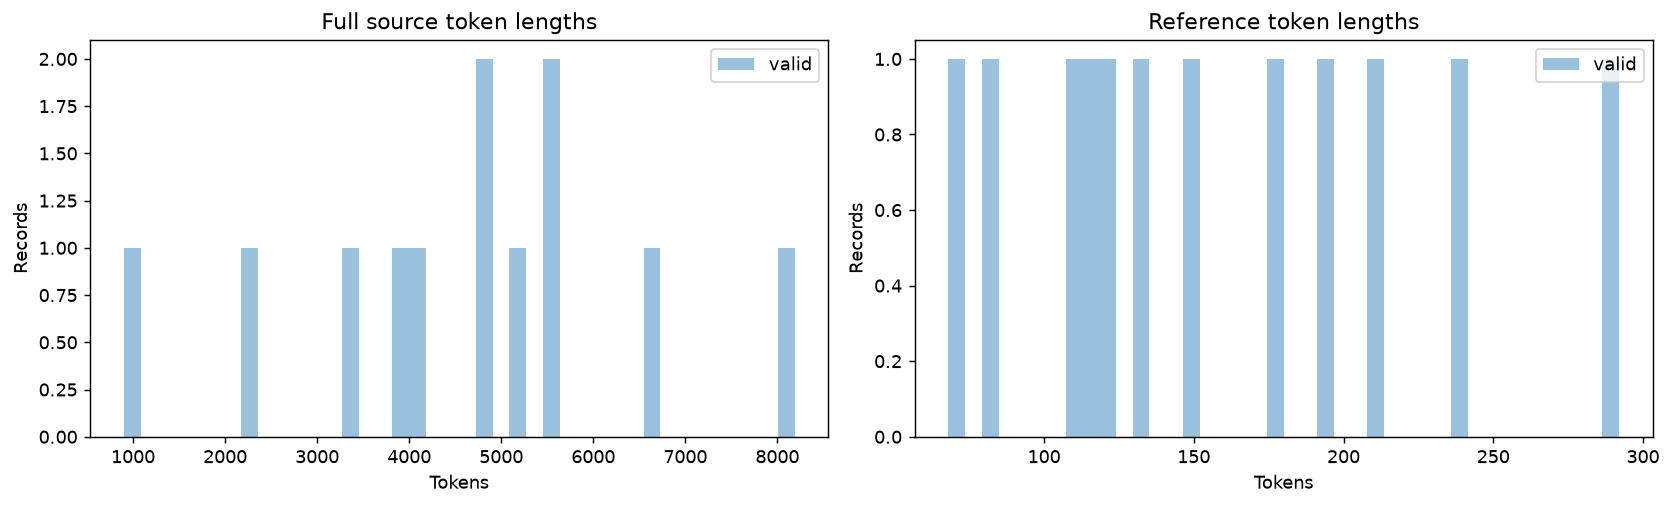

,split,source_index,doi,reasons
0,train,16,10.5446/18901 (DOI),[reused_abstract]
1,train,123,10.5446/19002 (DOI),[reused_abstract]
2,train,148,10.5446/18982 (DOI),[reused_abstract]
3,train,192,10.5446/59260 (DOI),[invalid_segment_times]
4,train,227,10.5446/54807 (DOI),[invalid_segment_times]
5,train,230,10.5446/37945 (DOI),[invalid_segment_times]
6,train,234,10.5446/19429 (DOI),[reused_abstract]
7,train,236,10.5446/19492 (DOI),[reused_abstract]
8,train,247,10.5446/21612 (DOI),[reused_abstract]
9,train,252,10.5446/51387 (DOI),[invalid_segment_times]


,source_tokens,reference_tokens,duration_minutes
count,12.000000,12.000000,12.000000
mean,4630.916667,157.833333,32.217056
std,1923.310851,67.000452,18.360352
min,898.000000,68.000000,5.230000
10%,2327.900000,85.500000,14.081066
50%,4825.500000,140.500000,29.867667
90%,6494.200000,237.200000,58.471799
99%,8011.550000,286.280000,70.763657
max,8187.000000,292.000000,71.954004


In [6]:
summary_df=pd.DataFrame([{key:row[key] for key in
    ('split','source_index','doi','genre','subject','duration_minutes','source_words',
     'abstract_words','source_tokens','reference_tokens','segment_count')} for row in items])
excluded_df=pd.DataFrame(metadata['excluded'],columns=['split','source_index','doi','reasons'])
display(pd.DataFrame([{'stage':'Source records','records':metadata['source_count']},
    {'stage':'Selected benchmark records','records':len(items)},
    {'stage':'Excluded records','records':len(excluded_df)}]))
display(summary_df.groupby('split').agg(records=('source_index','size'),
    source_tokens=('source_tokens','sum'),median_source_tokens=('source_tokens','median'),
    median_minutes=('duration_minutes','median')))
for field in ('genre','subject'):
    counts=summary_df[field].replace('', '(missing)').value_counts()
    display(pd.DataFrame({'records':counts,'percent':counts/len(items)*100}))
fig,axes=plt.subplots(1,2,figsize=(13,4))
for split,group in summary_df.groupby('split'):
    axes[0].hist(group['source_tokens'],bins=40,alpha=.45,label=split)
    axes[1].hist(group['reference_tokens'],bins=40,alpha=.45,label=split)
axes[0].set_title('Full source token lengths'); axes[1].set_title('Reference token lengths')
for ax in axes: ax.set_xlabel('Tokens'); ax.set_ylabel('Records'); ax.legend()
fig.tight_layout(); plt.show(); plt.close(fig)
print('Every excluded ID and reason:')
with pd.option_context('display.max_rows',None,'display.max_colwidth',None): display(excluded_df)
display(summary_df[['source_tokens','reference_tokens','duration_minutes']].describe(percentiles=[.1,.5,.9,.99]))

## 6. Lưu và kiểm tra nạp lại

Gói dữ liệu được ghi hoàn chỉnh vào file tạm rồi thay thế đích. Đọc lại file vừa ghi để xác nhận ID, nội dung và checksum. Không tạo receipt/manifest phụ.

In [7]:
require_frozen_cohort()  # Current decision is pending; no data/model execution.
if NEEDS_SAVE:
    saved=bundle_module.save_benchmark_bundle(bundle,BUNDLE_PATH,overwrite=BUNDLE_PATH.exists())
    print('Saved:',saved)
    # Release the original full corpus before checking the disk copy.
    before=metadata['selection_sha256']
    del items, metadata, bundle
    bundle=bundle_module.load_benchmark_bundle(BUNDLE_PATH)
    assert bundle['metadata']['selection_sha256']==before
    items=bundle['items']; metadata=bundle['metadata']
else:
    bundle_module.validate_bundle(bundle)
print('Reusable data:',BUNDLE_PATH)
print('Records:',len(items),'| compressed MiB:',round(BUNDLE_PATH.stat().st_size/2**20,2))

Saved: {'path': 'C:\\Users\\hung\\Documents\\GitHub\\multimodal-lecture-summarizer\\benchmark\\experiments\\outputs\\rq2_tib_benchmark\\limited\\tib-benchmark-data.jsonl.gz', 'bytes': 155379, 'payload_sha256': 'fb03f133e607506a0d536c16534b5d5d752d42d31bac2f859eec351701e47d58', 'records': 12}
Reusable data: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\benchmark\experiments\outputs\rq2_tib_benchmark\limited\tib-benchmark-data.jsonl.gz
Records: 12 | compressed MiB: 0.15


## 7. Đầu vào dùng chung cho S1 / S3

`generation_input` trả về nguồn đầy đủ và segment cho cả hai nhánh; `evaluation_target` trả về abstract riêng cho bộ chấm điểm. ID `split/source_index` được dùng xuyên suốt để ghép kết quả. Cùng một file dữ liệu có thể nạp lại trong notebook benchmark sau này mà không đọc lại Hugging Face.

In [8]:
benchmark_inputs=(bundle_module.generation_input(item) for item in items)
benchmark_targets={f"{item['split']}/{item['source_index']}":bundle_module.evaluation_target(item)
                   for item in items}
example=bundle_module.generation_input(items[0])
assert 'abstract' not in example and 'reference_text' not in example
print('Example generation ID:',example['id'])
print('Generation fields:',list(example))
print('Source preview:',example['transcript'][:400])
print('Paired candidates:',len(items),'| evaluation targets:',len(benchmark_targets))
ready={'status':'data_prepared','dataset':metadata['dataset'],'revision':metadata['revision'],
       'records':len(items),'selection_sha256':metadata['selection_sha256'],
       'data_file':str(BUNDLE_PATH),'arms':'S1 / S3','metric':BENCHMARK_CONFIG['primary_metric']}
display(pd.DataFrame([{'field':key,'value':value} for key,value in ready.items()]))
print('Preparation complete. Save this notebook with its outputs.')

Example generation ID: valid/269
Generation fields: ['id', 'split', 'source_index', 'doi', 'source_sha256', 'transcript', 'transcript_segments']
Source preview: Hi everyone. Oh, wow that is loud. I'm not used to talking on a microphone so this is going to be interesting. Okay, so I am Sharon and I'm going to be presenting this workshop today and I'm just going to go ahead and get started. So a great thing about the tech industry is that there is a ton of disruption and innovation. Unfortunately, there isn't a lot of that happening on the communications en
Paired candidates: 12 | evaluation targets: 12
Preparation complete. Save this notebook with its outputs.


,field,value
0,status,data_prepared
1,dataset,gigant/tib
2,revision,e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee
3,records,12
4,selection_sha256,2d5d1ae4659534059da907ad867e04e7cfee815cca2f84556e806e45b4ffc1bd
5,data_file,C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\benchmark\experiments\outputs\rq2_tib_benchmark\limited\tib-benchmark-data.jsonl.gz
6,arms,S1 / S3
7,metric,rouge_l_f1_against_creator_abstract


## 8. Nạp generator trên GPU

Dùng checkpoint/tokenizer đã khai báo ở đầu notebook. Chỉ một generator dùng chung cho cả S1 và S3.
Bộ chấm dùng encoder đa ngôn ngữ có revision cố định. BERTScore dùng thư viện chính thức với văn bản vừa cửa sổ encoder; văn bản dài hơn dùng phần mở rộng token-window được ghi rõ trong metadata. SBERTScore xử lý toàn bộ câu nguồn theo batch; câu quá dài được biểu diễn bằng trung bình có trọng số token qua mọi cửa sổ. Đây là cấu hình thích nghi đa ngôn ngữ, không phải tái lập nguyên checkpoint trong bài báo.


In [9]:
require_frozen_cohort()  # Current decision is pending; no data/model execution.
import torch
if not torch.cuda.is_available():
    raise RuntimeError('Chọn GPU trong Runtime → Change runtime type để chạy generation.')
import gc
for model_name in ('backend','semantic_scorer'):
    globals().pop(model_name,None)
gc.collect()
torch.cuda.empty_cache()
from huggingface_hub import snapshot_download
default_model_dir = Path('/content/rq2_tib_generator') if IN_COLAB else Path.cwd() / 'experiments/outputs/rq2_tib_model'
MODEL_DIR=Path(os.environ.get('RQ2_TIB_MODEL_DIR',str(default_model_dir)))
model_cached=(MODEL_DIR/'model.safetensors').is_file() and (MODEL_DIR/'tokenizer.json').is_file()
snapshot_download(repo_id=MODEL_ID,revision=MODEL_REVISION,local_dir=str(MODEL_DIR),
                  local_files_only=model_cached)
backend=backend_module.LocalHfUsageBackend(MODEL_DIR,model_id=MODEL_ID,
                                         revision=MODEL_REVISION,device='cuda')
# Release preparation corpus; the benchmark loads its shared data entry point.
for prepared_name in ('benchmark_inputs','benchmark_targets','items','metadata','bundle'):
    globals().pop(prepared_name,None)
# Execution settings are recorded per arm; existing completed predictions resume.
MAP_BATCH_SIZE=2  # Fixed measured T4 pilot profile; do not auto-increase.
backend.map_batch_size=MAP_BATCH_SIZE
print('Generator:',backend.model_id,'| device:',backend.device,'| map batch:',MAP_BATCH_SIZE)


Generator: Qwen/Qwen2.5-1.5B-Instruct@989aa7980e4cf806f80c7fef2b1adb7bc71aa306 | device: cuda | map batch: 2


## 9. Cấu hình lần chạy và log chi tiết

Log hiển thị tên công đoạn, ID bài, S1/S3, map/reduce, số đoạn hoặc số câu đã xử lý. Vùng log giữ 60 sự kiện gần nhất; mốc tổng tiến độ được in mỗi 25 bài. Trạng thái generation và evaluation luôn được ghi riêng.

Performance profile: map batches default to 8; set MAP_BATCH_SIZE in the generator cell to 4 or 2 if needed. Stop the previous session before opening this updated notebook and resume the same Drive output directory. Completed predictions are reused. FP16 batched decoding may differ numerically from serial decoding; each new arm records its batch size, and the cost report shows the profile distribution. Exact legacy chunk boundaries and per-arm token allocations are preserved. Speedup has not yet been measured on GPU.


In [10]:
require_frozen_cohort()  # Current decision is pending; no data/model execution.
import json
import time
from collections import deque
from datetime import datetime
from html import escape
from IPython.display import HTML
from types import SimpleNamespace

# Keep detailed live logs bounded: 60 recent events, no separate receipt file.
log_tail=deque(maxlen=60)
log_view=None
last_render=0.0

def begin_log(title):
    global log_view,last_render
    log_tail.clear()
    log_view=display(HTML('<pre>'+escape(title)+'</pre>'),display_id=True)
    last_render=0.0

def log_event(event):
    global last_render
    stamp=datetime.now().strftime('%H:%M:%S')
    item=f"{event.get('index','-')}/{event.get('total','-')} {event.get('id','')}"
    details={key:value for key,value in event.items() if key not in ('index','total','id')}
    log_tail.append(f"[{stamp}] {item} {json.dumps(details,ensure_ascii=False,default=str)}")
    now=time.monotonic()
    if now-last_render>=2.0 or event.get('status')=='failed':
        if log_view is not None:
            log_view.update(HTML('<pre style="max-height:600px;overflow:auto">'+escape('\n'.join(log_tail))+'</pre>'))
        last_render=now

def report_progress(phase,index,total,row):
    if index==1 or index%25==0 or index==total:
        print(f"[{phase}] {index}/{total} | {row['id']} | generation={row['status']} | "
              f"evaluation={row.get('evaluation_status','not_run')}",flush=True)

config=benchmark_module.BenchmarkConfig(
    chunk_tokens=BENCHMARK_CONFIG['chunk_tokens'],
    map_output_tokens=BENCHMARK_CONFIG['map_max_new_tokens'],
    final_output_tokens=BENCHMARK_CONFIG['final_max_new_tokens'],
    temperature=BENCHMARK_CONFIG['temperature'],seed=BENCHMARK_CONFIG['seed'],
    bootstrap_samples=BENCHMARK_CONFIG['paired_analysis']['bootstrap_samples'],
    bootstrap_seed=BENCHMARK_CONFIG['paired_analysis']['seed'])
# Preserve the existing generation directory across scoring/logging changes.
cache_config={**BENCHMARK_CONFIG,'paired_analysis':{'contrast':'S3-S1','bootstrap_samples':5000,'seed':20261009}}
run_key=benchmark_module._hash({'config':cache_config,'selection':ready['selection_sha256']})[:16]
RUN_DIR=OUTPUT_DIR/'runs'/run_key
# Only identities are needed by evaluation; it cannot call generator methods.
evaluation_backend=SimpleNamespace(model_id=backend.model_id,tokenizer_id=backend.tokenizer_id)
print('Results:',RUN_DIR)


Results: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\benchmark\experiments\outputs\rq2_tib_benchmark\limited\runs\df5415e7c530a06e


## 10. Sinh tóm tắt S1/S3 và chấm ROUGE-L

Cell này chỉ sinh tóm tắt và tính ROUGE-L; chưa nạp BERTScore/SBERTScore. Log báo phân đoạn, mỗi đoạn map và bước reduce của từng nhánh. Predictions đã hoàn tất được dùng lại; không cần xử lý lại dữ liệu trước vì `run_benchmark` tự gọi preprocessing.


In [ ]:
require_frozen_cohort()  # Current decision is pending; no data/model execution.
if 'backend' not in globals():
    raise RuntimeError('Nạp lại generator ở bước 8 trước khi chạy generation.')
begin_log('Generation S1/S3')
generated=benchmark_module.run_benchmark(
    backend,data_path=BUNDLE_PATH,output_dir=RUN_DIR,config=config,
    phase='generate',summarize=False,on_event=log_event,
    progress=lambda index,total,row:report_progress('GENERATION',index,total,row))
print('Generation cell finished; semantic evaluation runs in the next stage.')


## 11. Kiểm tra coverage generation

Bảng này cho biết bao nhiêu bài đã có cặp S1/S3, bao nhiêu bài lỗi và bao nhiêu bài đã được chấm ngữ nghĩa từ lần chạy trước. Lỗi generation giữ ID để lần chạy sau tiếp tục.


In [ ]:
generation_counts=pd.Series([row['status'] for row in generated['results']]).value_counts()
display(generation_counts.rename('records').to_frame())
generation_failures=pd.DataFrame([
    {'id':row['id'],'status':row['status'],'error':row.get('error','')}
    for row in generated['results'] if row['status']!='completed'])
display(generation_failures)
print('Existing semantic results:',sum(row.get('evaluation_status')=='completed' for row in generated['results']))


## 12. Release generator and load evaluation encoders

Evaluation uses CUDA when available, after releasing the generator; CPU is the fallback. Model identities, metrics and full-source policies stay fixed. The evaluator device is recorded and changes invalidate only evaluation, never saved generation. Reload the generator cell before returning to generation.


In [ ]:
require_frozen_cohort()  # Current decision is pending; no data/model execution.
begin_log('Loading metric encoders')
import gc
if 'backend' in globals():
    del backend
if 'generated' in globals():
    del generated
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
metrics_module=sys.modules['experiments.scripts.rq2_tib_benchmark_metrics']
semantic_scorer=metrics_module.SemanticScorer(
    device='cuda' if torch.cuda.is_available() else 'cpu',
    batch_size=16,on_event=log_event)
print('Loading evaluation encoders; no summaries are generated here.',flush=True)
semantic_scorer.load()
display(pd.DataFrame([{'setting':key,'value':value} for key,value in semantic_scorer.metadata.items()]))
print('Evaluation encoders ready.')


## 13. Chấm BERTScore và SBERTScore trên predictions đã lưu

Cell này không sinh tóm tắt. Log báo BERTScore từng nhánh, số câu transcript đã được embedding và điểm SBERTScore. Điểm đã chấm với cùng cấu hình được dùng lại; lỗi metric được lưu riêng để retry. Nếu thiếu checkpoint generation, cell yêu cầu hoàn tất bước generation trước.


In [ ]:
require_frozen_cohort()  # Current decision is pending; no data/model execution.
begin_log('BERTScore and SBERTScore evaluation')
benchmark=benchmark_module.run_benchmark(
    evaluation_backend,data_path=BUNDLE_PATH,output_dir=RUN_DIR,config=config,
    phase='evaluate',summarize=False,semantic_scorer=semantic_scorer,on_event=log_event,
    progress=lambda index,total,row:report_progress('EVALUATION',index,total,row))
print('Evaluation complete:',sum(row.get('evaluation_status')=='completed' for row in benchmark['results']))
print('Evaluation failed:',sum(row.get('evaluation_status')=='failed' for row in benchmark['results']))


## 14. Tổng hợp ba metric và paired bootstrap

Chỉ dùng điểm đã lưu, không nạp model hay gọi generation. Mỗi metric báo số cặp đã chấm và CI95 cho S3−S1, với 5.000 resamples. Chi phí từng ứng viên gồm các lần thất bại có receipt, không cộng lặp phần reused. Chi phí evaluation được báo riêng.


In [ ]:
require_frozen_cohort()  # Current decision is pending; no data/model execution.
begin_log('Aggregation and paired bootstrap')
log_event({'stage':'aggregation','status':'started','samples':config.bootstrap_samples})
benchmark=benchmark_module.summarize_benchmark(benchmark,output_dir=RUN_DIR,config=config)
summary=benchmark['summary']
log_event({'stage':'aggregation','status':'completed','metrics':list(summary['metrics'])})
print('Summary:',RUN_DIR/'summary.json')


## 15. Điểm trung bình và khoảng tin cậy


In [ ]:
summary=benchmark['summary']
print('Generation coverage')
display(pd.DataFrame([summary['overall']]))
metric_rows=[]
for metric, report in summary['metrics'].items():
    interval=report['paired_bootstrap']['ci95']
    metric_rows.append({'metric':metric, **report['overall'],
                        'delta_ci_low':interval[0] if interval else None,
                        'delta_ci_high':interval[1] if interval else None})
metric_df=pd.DataFrame(metric_rows).set_index('metric')
display(metric_df)
fig,axes=plt.subplots(1,3,figsize=(15,3))
for axis,(metric,report) in zip(axes,summary['metrics'].items()):
    interval=report['paired_bootstrap']['ci95']
    delta=report['overall']['S3_minus_S1']
    if interval is not None:
        axis.hlines(0,interval[0],interval[1],linewidth=3)
        axis.plot(delta,0,'o')
    axis.axvline(0,color='black',linestyle='--')
    axis.set_title(metric+' Δ and CI95'); axis.set_yticks([])
fig.tight_layout(); plt.show(); plt.close(fig)
print('Metric evaluation coverage and configuration')
display(pd.DataFrame([summary['evaluation']]))


## 16. Nhận xét và phân tích theo nhóm

CI chứa 0 nghĩa là chưa đủ bằng chứng về hướng khác biệt; không kết luận hai phương pháp tương đương. Phân nhóm là phân tích mô tả. SBERTScore không được chuyển thành phần trăm factual.


In [ ]:
for metric, report in summary['metrics'].items():
    interval=report['paired_bootstrap']['ci95']
    if interval is None:
        print(metric, ': chưa có đủ cặp được chấm.')
    elif interval[0]>0:
        print(metric, ': CI của S3−S1 nằm trên 0; dữ liệu hỗ trợ S3 cao hơn ở metric này.')
    elif interval[1]<0:
        print(metric, ': CI của S3−S1 nằm dưới 0; dữ liệu hỗ trợ S1 cao hơn ở metric này.')
    else:
        print(metric, ': CI chứa 0; chưa đủ bằng chứng về hướng khác biệt.')
    for field,groups in report['strata'].items():
        print(metric, field)
        display(pd.DataFrame.from_dict(groups,orient='index'))


## 17. Kết quả từng bài và danh sách lỗi


In [ ]:
rows=[]
for result in benchmark['results']:
    row={key:result.get(key) for key in ('id','split','genre','subject','status','seconds',
                                       'evaluation_status','evaluation_error','evaluation_seconds')}
    if result['status']=='completed':
        metrics={'rouge_l':result['scores'], **result.get('semantic_scores',{})}
        for metric,scores in metrics.items():
            for name in ('S1','S3','S3_minus_S1'): row[metric+'_'+name]=scores[name]
    for arm,receipt in result.get('arms',{}).items():
        for field in ('prompt_tokens','output_tokens','segmentation_seconds','generation_seconds',
                      'wall_seconds','call_count','peak_gpu_allocated_bytes'):
            row[arm+'_'+field]=receipt.get(field)
    row['error']=result.get('error','')
    rows.append(row)
result_df=pd.DataFrame(rows)
display(result_df)
failed_df=result_df.loc[result_df['status'].ne('completed') | result_df['evaluation_status'].eq('failed')]
with pd.option_context('display.max_rows',None,'display.max_colwidth',None): display(failed_df)


## 18. Phân bố điểm và chênh lệch S3−S1


In [ ]:
fig,axes=plt.subplots(3,2,figsize=(12,12))
for index,metric in enumerate(('rouge_l','bertscore','sbertscore')):
    columns=[metric+'_'+name for name in ('S1','S3','S3_minus_S1')]
    if all(column in result_df for column in columns):
        complete=result_df[columns].dropna()
        axes[index,0].hist(complete[columns[0]],bins=30,alpha=.5,label='S1')
        axes[index,0].hist(complete[columns[1]],bins=30,alpha=.5,label='S3')
        axes[index,0].legend()
        axes[index,1].hist(complete[columns[2]],bins=30)
    axes[index,0].set_title(metric+' scores')
    axes[index,1].axvline(0,color='black',linestyle='--')
    axes[index,1].set_title(metric+' paired S3−S1')
fig.tight_layout(); plt.show(); plt.close(fig)


## 19. Chi phí riêng từng ứng viên

Thời gian phân đoạn, generation, lời gọi, token và GPU peak được báo riêng. GPU peak là bộ nhớ tuyệt đối gồm model đã nạp; timing cũ chưa đo vẫn là thiếu dữ liệu.

Tài liệu: [BERTScore](https://arxiv.org/abs/1904.09675), [SBERTScore](https://arxiv.org/abs/2409.15090). Cấu hình đa ngôn ngữ và phần mở rộng xử lý văn bản dài được ghi trong metadata, không coi là tái lập nguyên checkpoint bài báo.


In [ ]:
print('Costs per candidate: all attempts, excluding reused receipts')
cost_df=pd.DataFrame.from_dict(summary['resources_by_arm'],orient='index')
display(cost_df)
print('Shared/total costs')
display(pd.DataFrame([summary['resources']]))
fig,axes=plt.subplots(1,3,figsize=(15,4))
for axis,field in zip(axes,('wall_seconds','prompt_tokens','output_tokens')):
    if cost_df[field].notna().any():
        cost_df[field].plot.bar(ax=axis,rot=0)
    axis.set_title(field)
fig.tight_layout(); plt.show(); plt.close(fig)
print('Save notebook with outputs. Re-run to resume generation and metric evaluation independently.')

from collections import Counter
profiles=Counter((name,arm.get('map_batch_size','legacy serial'))
                 for row in benchmark['results']
                 for name,arm in row.get('arms',{}).items())
display(pd.DataFrame([{'arm':arm,'map_batch_size':batch,'records':count}
                      for (arm,batch),count in profiles.items()]))
